In [1]:
import numpy as np
inf=float("inf")

import pandas as pd

from scipy.spatial.distance import cdist, pdist, squareform


import matplotlib.pyplot as plt
plt.style.use('ggplot')

import scipy.stats as st

import stablerank.srank as sr
import geometry_objects_2021 as ge

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

import _pickle as pickle

from ripser import ripser


from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, cophenet
import scipy.spatial as spatial

# From distances to dendrograms

In [4]:

data = np.array([[1,1],[1,2],[2,1],[2,2],[1,7],[1,0]], dtype="double")
dist = pdist(data, "euclidean")

data1 = np.array([[1,1],[2,1],[2,2],[1,7],[1,2],[1,0]], dtype="double")
dist1 = pdist(data1, "euclidean")


In [6]:
print(squareform(dist))
print("*"*120)
print(squareform(dist1))

[[0.         1.         1.         1.41421356 6.         1.        ]
 [1.         0.         1.41421356 1.         5.         2.        ]
 [1.         1.41421356 0.         1.         6.08276253 1.41421356]
 [1.41421356 1.         1.         0.         5.09901951 2.23606798]
 [6.         5.         6.08276253 5.09901951 0.         7.        ]
 [1.         2.         1.41421356 2.23606798 7.         0.        ]]
************************************************************************************************************************
[[0.         1.         1.41421356 6.         1.         1.        ]
 [1.         0.         1.         6.08276253 1.41421356 1.41421356]
 [1.41421356 1.         0.         5.09901951 1.         2.23606798]
 [6.         6.08276253 5.09901951 0.         5.         7.        ]
 [1.         1.41421356 1.         5.         0.         2.        ]
 [1.         1.41421356 2.23606798 7.         2.         0.        ]]


In [8]:
L = linkage(dist, "ward")
print(L)

[[0.         1.         1.         2.        ]
 [2.         3.         1.         2.        ]
 [6.         7.         1.41421356 4.        ]
 [5.         8.         2.         5.        ]
 [4.         9.         7.5055535  6.        ]]


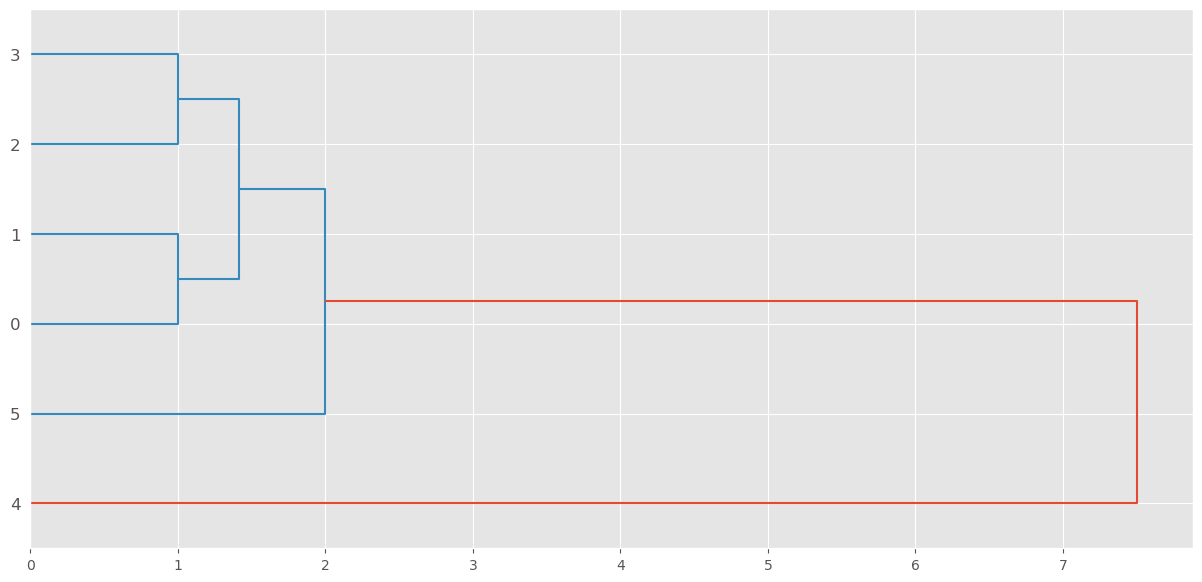

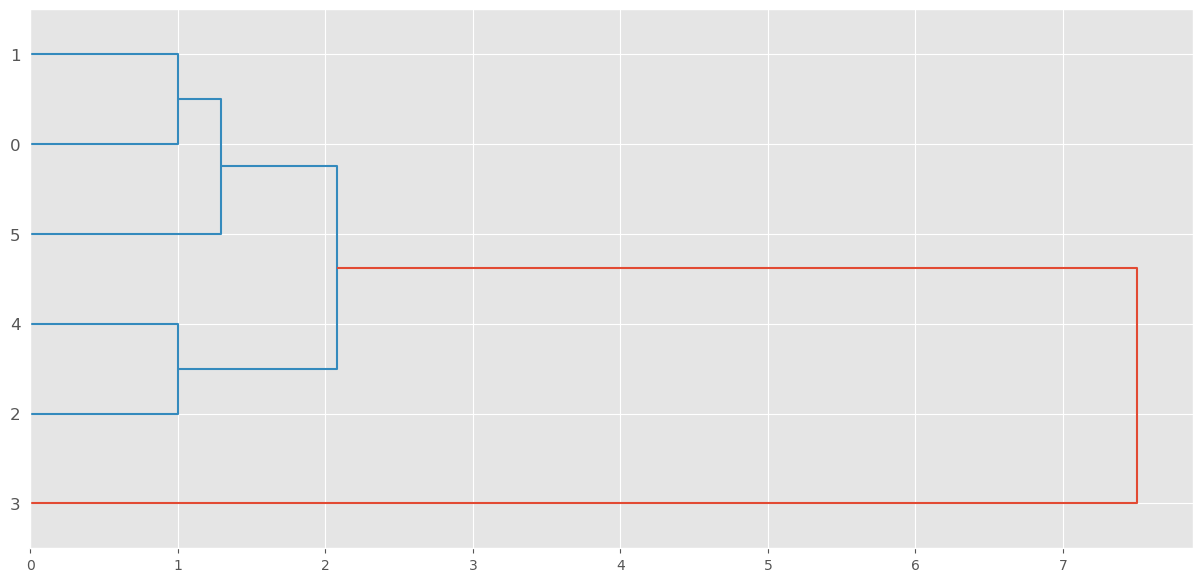

In [10]:
fig = plt.figure("0", figsize=(15,7))
L = linkage(dist, "ward")
dn=dendrogram(L, orientation='right')

fig = plt.figure("1", figsize=(15,7))
L = linkage(dist1, "ward")
dn=dendrogram(L, orientation='right')

## From dendrograms to ultra metrics

In [13]:
print("dist: ")
print(squareform(dist))
L = linkage(dist, "ward")

print("*"*120)

dist_ultra = cophenet(L)
print("dist_ultra: ")
print(squareform(dist_ultra))


dist: 
[[0.         1.         1.         1.41421356 6.         1.        ]
 [1.         0.         1.41421356 1.         5.         2.        ]
 [1.         1.41421356 0.         1.         6.08276253 1.41421356]
 [1.41421356 1.         1.         0.         5.09901951 2.23606798]
 [6.         5.         6.08276253 5.09901951 0.         7.        ]
 [1.         2.         1.41421356 2.23606798 7.         0.        ]]
************************************************************************************************************************
dist_ultra: 
[[0.         1.         1.41421356 1.41421356 7.5055535  2.        ]
 [1.         0.         1.41421356 1.41421356 7.5055535  2.        ]
 [1.41421356 1.41421356 0.         1.         7.5055535  2.        ]
 [1.41421356 1.41421356 1.         0.         7.5055535  2.        ]
 [7.5055535  7.5055535  7.5055535  7.5055535  0.         7.5055535 ]
 [2.         2.         2.         2.         7.5055535  0.        ]]


## From dendrograms to barcodes

type of b:  <class 'stablerank.barcodes.BC'>


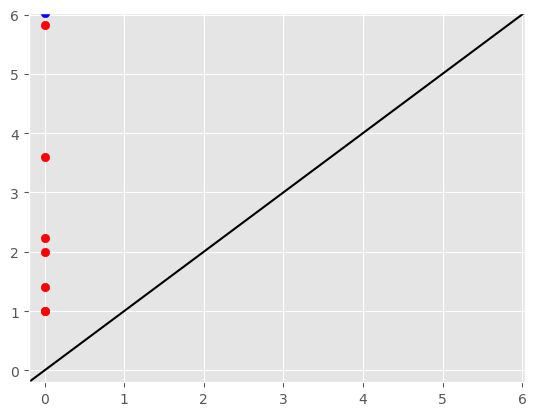

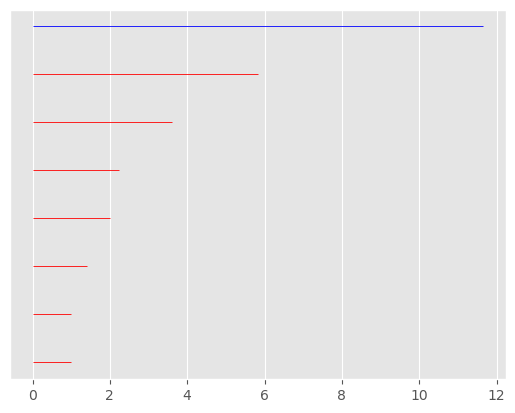

In [16]:
data = [[0,0], [1,1],[2,1],[3,2],[-1,1],[4,2],[-1,-1],[2,-1]]
dist = spatial.distance.pdist(data, "euclidean")
cm = "complete"

L = linkage(dist, cm)

b = sr.linkage_to_bc(L)

print("type of b: ", type(b))

plt.figure("persitance diagram")
b.persistence_diagram()

plt.figure("bar code")
b.plot()

## From bar code to PCF

<class 'stablerank.rtorf.Pcnif'>


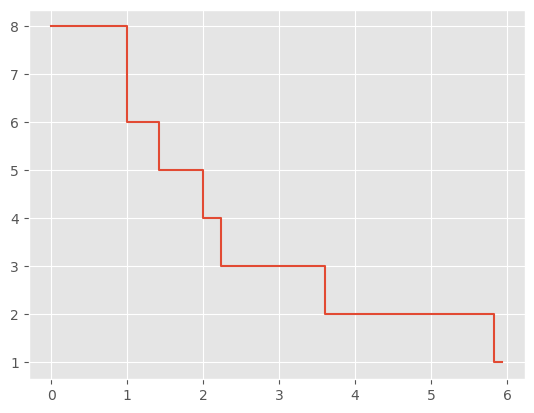

In [19]:
f = b.stable_rank()
print(type(f))
f.plot()

## From distance to PCF

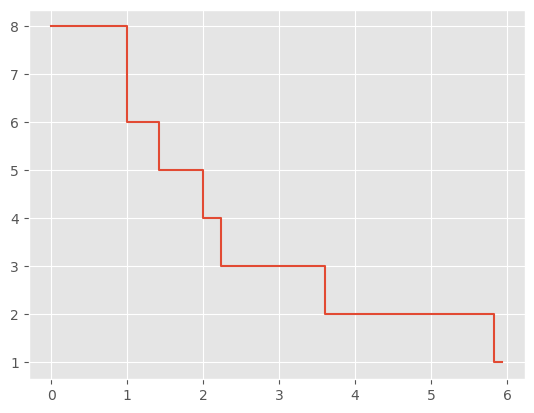

In [22]:
data = [[0,0], [1,1],[2,1],[3,2],[-1,1],[4,2],[-1,-1],[2,-1]]
dist = spatial.distance.pdist(data, "euclidean")


cm = "complete"

D = sr.Distance(squareform(dist))
g = D.get_h0sr(clustering_method=cm, reduced=False)
g.plot()

## Examples of hierarchical clustering

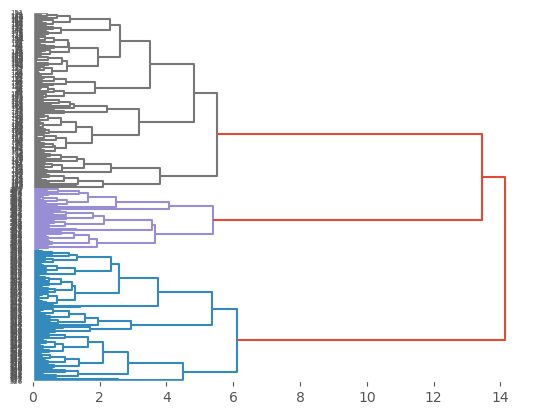

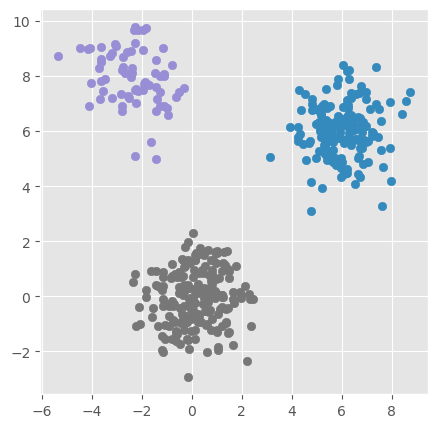

In [25]:
point1 = [0,0]
number_points1 = 200
point2 = [6,6]
number_points2 = 150
point3 = [-2,8]
number_points3 = 70
data1 = ge.normal_point(point1, number_points1)
data2 = ge.normal_point(point2, number_points2)
data3 = ge.normal_point(point3, number_points3)

data = np.vstack([data1, data2, data3])
dist= pdist(data, "euclidean")



cm = "complete"
L = linkage(dist, cm)
plt.figure("dendrogram "+cm)
dn=dendrogram(L, orientation='right')


plt.figure(figsize=(5,5))
for i in range(len(dn['leaves'])):
    point = data[dn['leaves'][i]]
    color = dn['leaves_color_list'][i]
    plt.scatter(point[0], point[1], color=color)


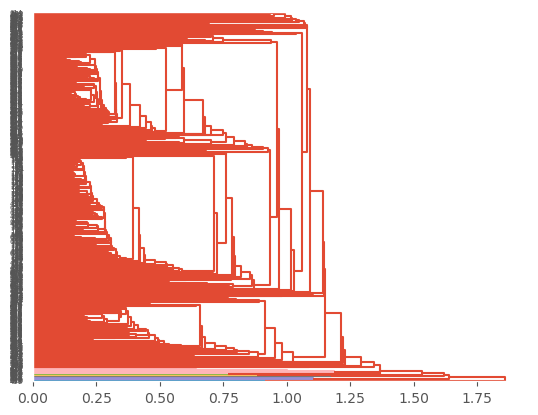

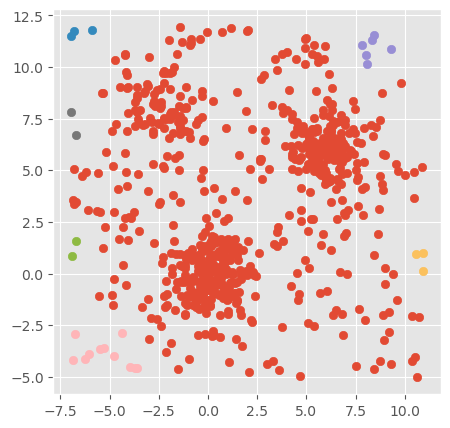

In [26]:
noise = ge.uniform_noise(-7, 11, -5, 12, 300)
data_noisy =  np.vstack([data, noise])
dist_noisy= pdist(data_noisy, "euclidean")

cm = "single"
L = linkage(dist_noisy, cm)
plt.figure("dendrogram "+cm)
dn=dendrogram(L, orientation='right')


plt.figure(figsize=(5,5))
for i in range(len(dn['leaves'])):
    point = data_noisy[dn['leaves'][i]]
    color = dn['leaves_color_list'][i]
    plt.scatter(point[0], point[1], color=color)


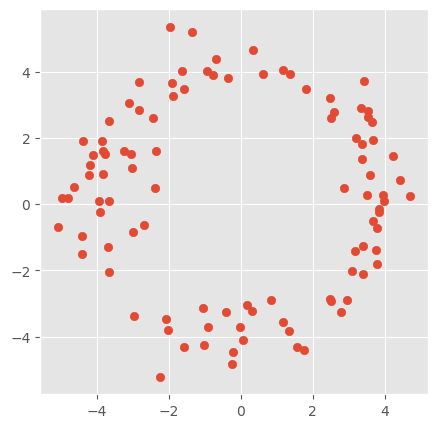

In [27]:
center = [0,0]
r = np.double(4)
number_points = 100
error=1
circle = ge.circle(center,r,number_points, error)
plt.figure(figsize=(5,5))
plt.scatter(circle[:,0], circle[:,1])

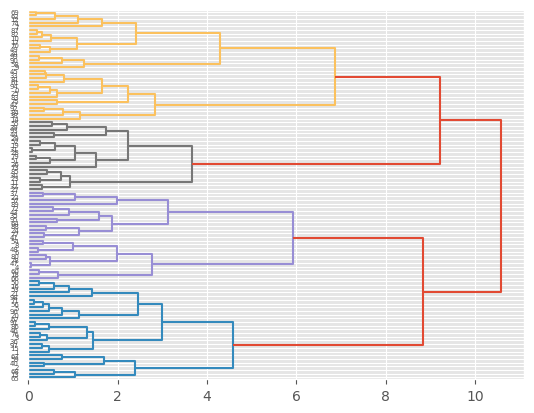

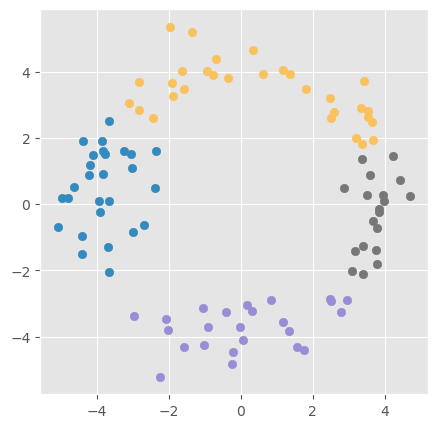

In [29]:
dist= pdist(circle, "euclidean")
L = linkage(dist, "complete")
dn=dendrogram(L, orientation='right')

plt.figure(figsize=(5,5))
for i in range(len(dn['leaves'])):
    point = circle[dn['leaves'][i]]
    color = dn['leaves_color_list'][i]
    plt.scatter(point[0], point[1], color=color)


## Circle vs square

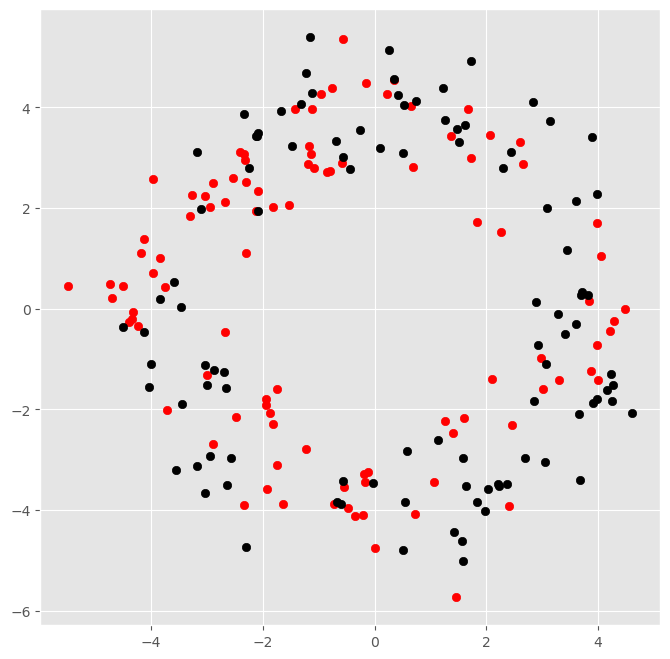

In [31]:
center = np.array([0,0], dtype="double")
r = np.double(4)


vertices = [[0,4.6], [-4.6,0],[0,-4.6],[4.6,0]]

number_points = 100
error = 1


circle = ge.circle(center,r,number_points, error)

square = ge.closed_path(vertices, number_points, error)

plt.figure(figsize=(8,8))
plt.scatter(square[:,0], square[:,1], color="red")
plt.scatter(circle[:,0], circle[:,1], color="black")

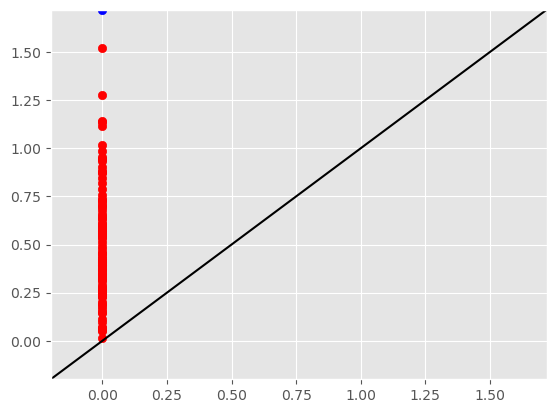

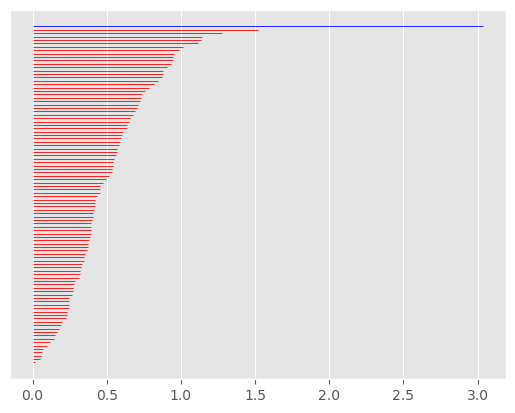

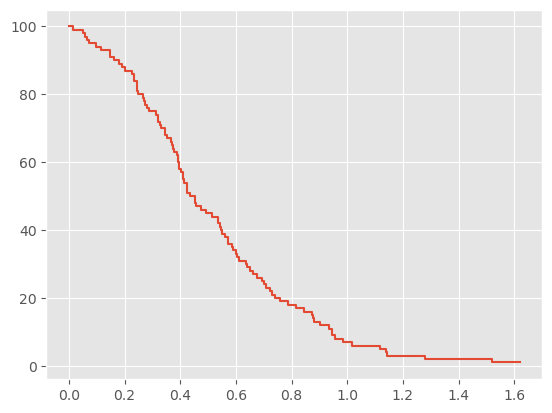

In [32]:
cm = "single"

dist = spatial.distance.pdist(circle, "euclidean")

link = linkage(dist, cm)

b = sr.linkage_to_bc(link)
f_circle = sr.linkage_to_sr(link)

plt.figure("persitance diagram")
b.persistence_diagram()

plt.figure("bar code")
b.plot()

plt.figure("pcf")
f_circle.plot()

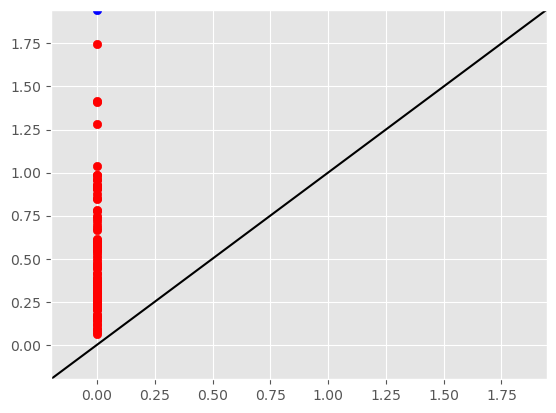

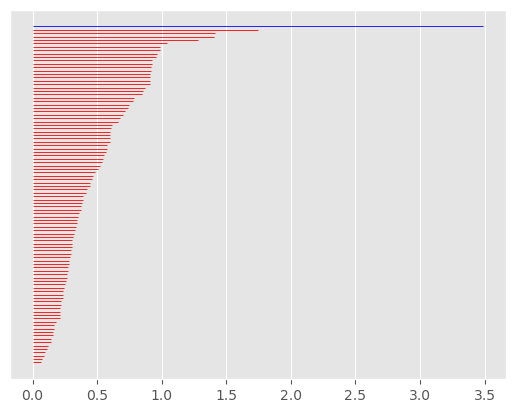

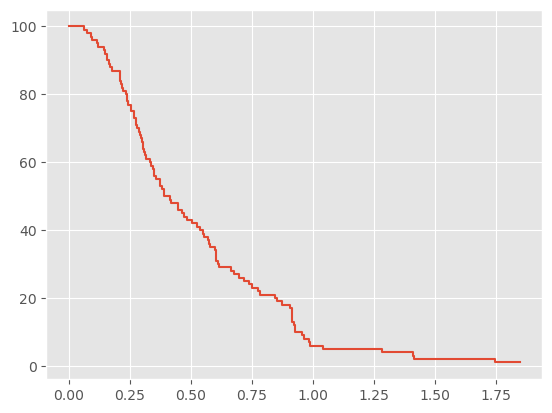

In [33]:

dist = spatial.distance.pdist(square, "euclidean")

link = linkage(dist, cm)

b = sr.linkage_to_bc(link)
f_square = sr.linkage_to_sr(link)

plt.figure("persitance diagram")
b.persistence_diagram()

plt.figure("bar code")
b.plot()

plt.figure("pcf")
f_square.plot()

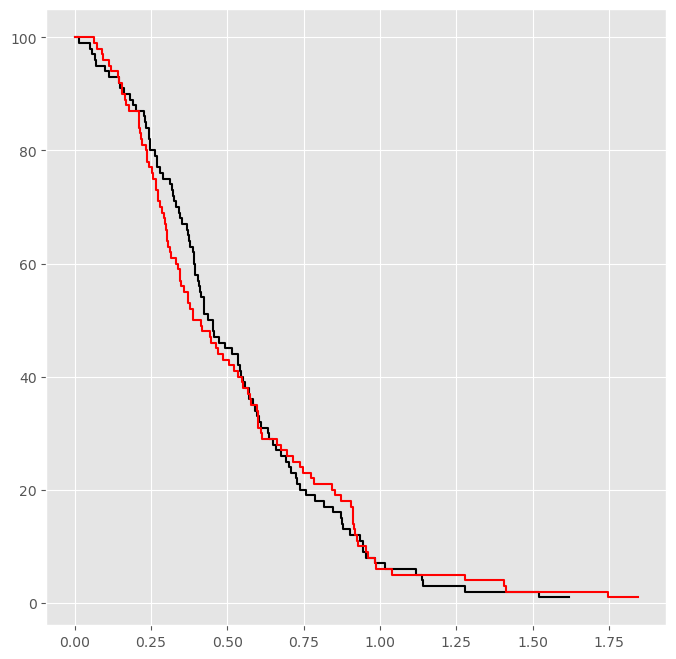

In [35]:
plt.figure(figsize=(8,8))
f_circle.plot(color="black")
f_square.plot(color="red")

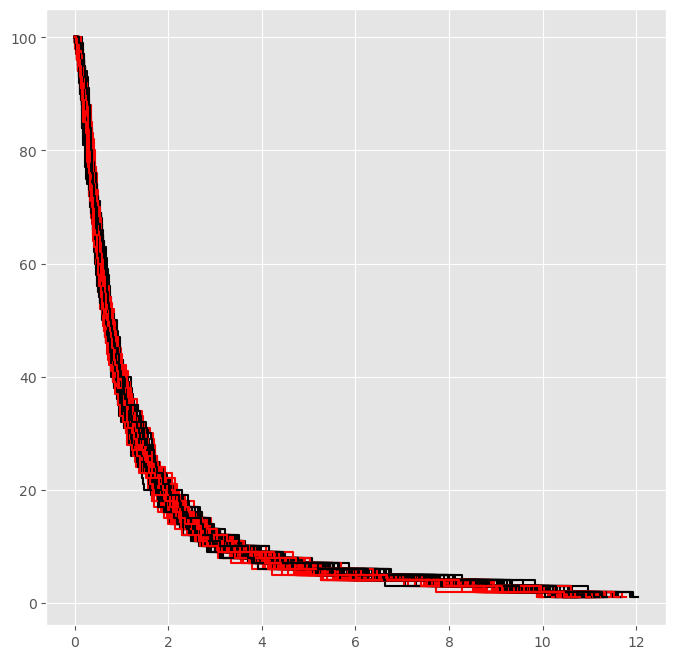

In [39]:
cm = "complete"

plt.figure(figsize=(8,8))

number_tries = 100
for i in range(number_tries):
    figure = ge.circle(center,r,number_points, error)
    dist = spatial.distance.pdist(figure, "euclidean")
    link = linkage(dist, cm)
    f_circle = sr.linkage_to_sr(link)
    f_circle.plot(color="black")
    
    figure = ge.closed_path(vertices, number_points, error)
    dist = spatial.distance.pdist(figure, "euclidean")
    link = linkage(dist, cm)
    f_square = sr.linkage_to_sr(link)
    f_square.plot(color="red")

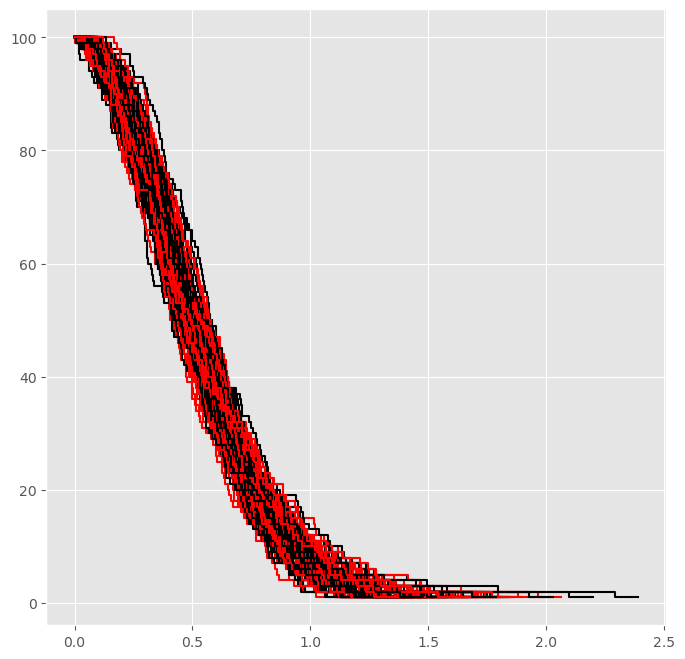

In [44]:
cm = "single"


plt.figure(figsize=(8,8))

number_tries = 100
for i in range(number_tries):
    figure = ge.circle(center,r,number_points, error)
    dist = spatial.distance.pdist(figure, "euclidean")
    link = linkage(dist, cm)
    f_circle = sr.linkage_to_sr(link)
    f_circle.plot(color="black")
    
    figure = ge.closed_path(vertices, number_points, error)
    dist = spatial.distance.pdist(figure, "euclidean")
    link = linkage(dist, cm)
    f_square = sr.linkage_to_sr(link)
    f_square.plot(color="red")

In [46]:
cm = "complete"
f_circle = sr.zero_pcnif()
f_square = sr.zero_pcnif()

number_tries = 1000
for i in range(number_tries):
    circle = ge.circle(center,r,number_points, error)
    dist = spatial.distance.pdist(circle, "euclidean")
    link = linkage(dist, cm)
    f_circle += sr.linkage_to_sr(link)

    square = ge.closed_path(vertices, number_points, error)
    dist = spatial.distance.pdist(square, "euclidean")
    link = linkage(dist, cm)
    f_square += sr.linkage_to_sr(link)
    
f_circle = f_circle * (1/number_tries) 
f_square = f_square * (1/number_tries) 

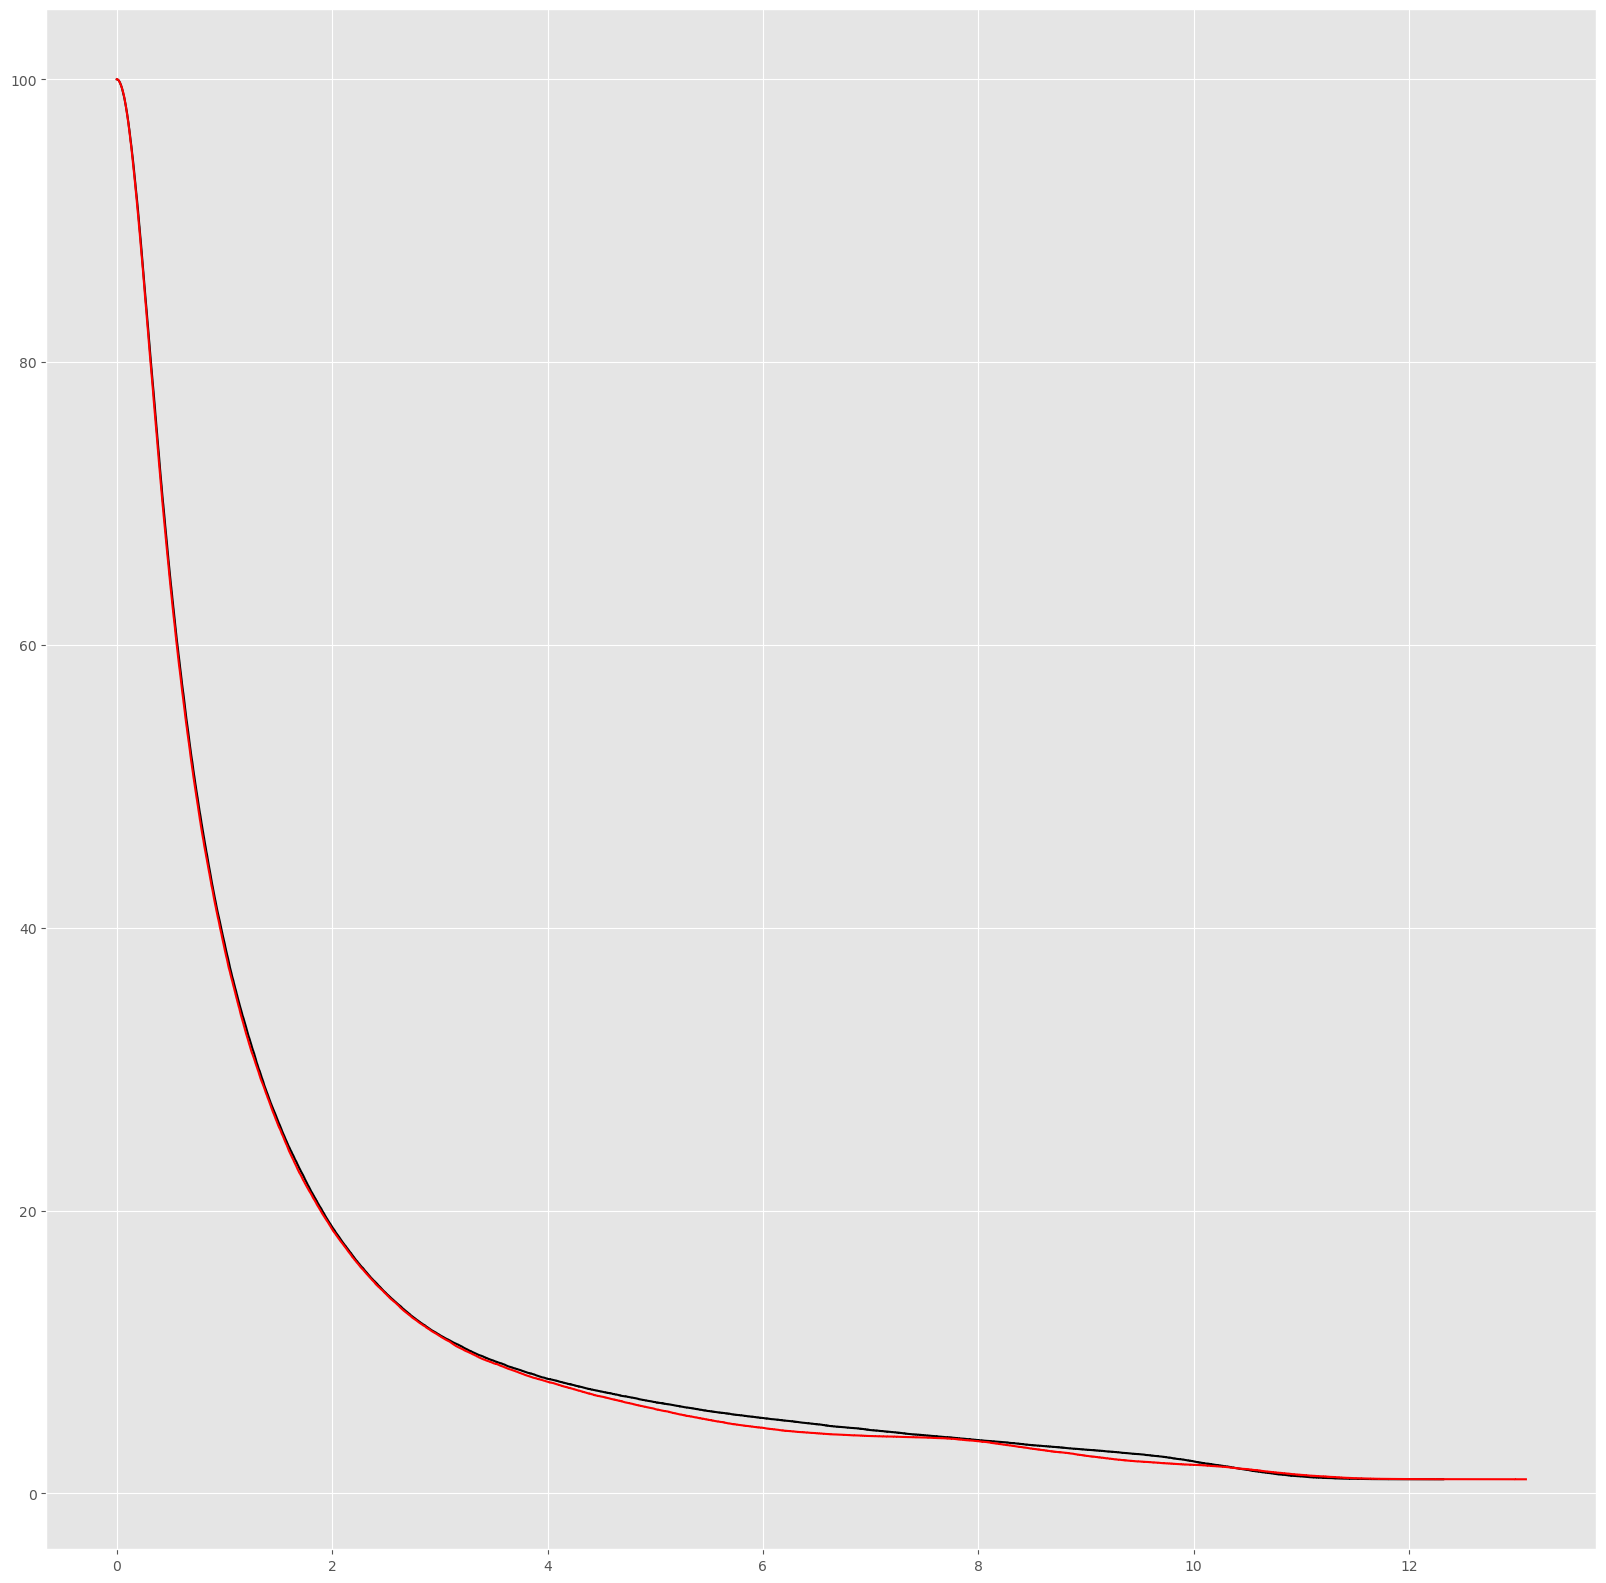

In [47]:
plt.figure(figsize=(20,20))
f_circle.plot(color="black")
f_square.plot(color="red")

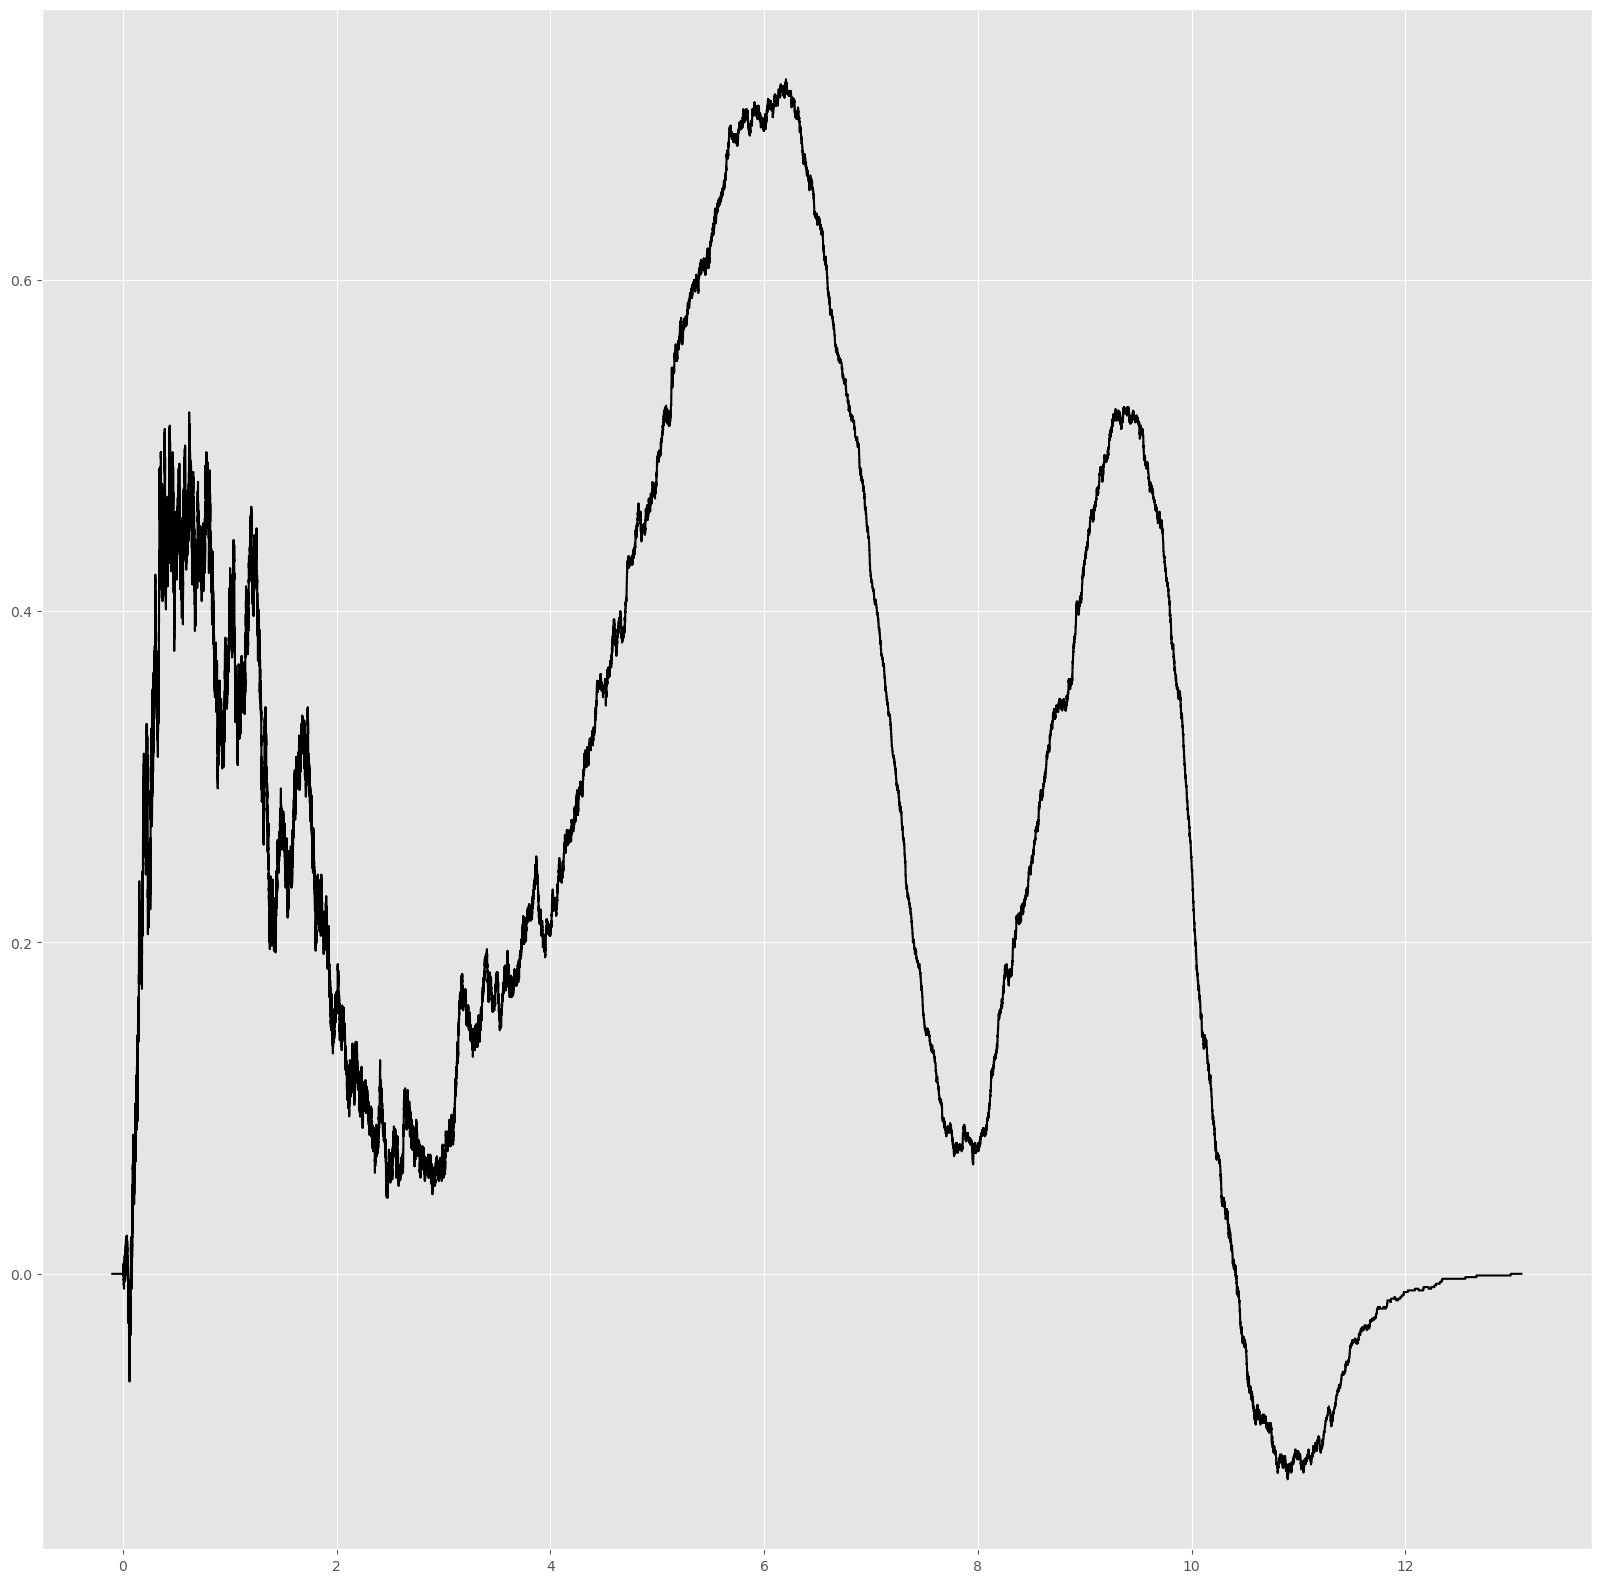

In [48]:
plt.figure(figsize=(20,20))
(f_circle-f_square).plot(color="black")

In [49]:
cm = "single"
f_circle = sr.zero_pcnif()
f_square = sr.zero_pcnif()

number_tries = 1000
for i in range(number_tries):
    circle = ge.circle(center,r,number_points, error)
    dist = spatial.distance.pdist(circle, "euclidean")
    link = linkage(dist, cm)
    f_circle += sr.linkage_to_sr(link)

    square = ge.closed_path(vertices, number_points, error)
    dist = spatial.distance.pdist(square, "euclidean")
    link = linkage(dist, cm)
    f_square += sr.linkage_to_sr(link)
    
f_circle = f_circle * (1/number_tries) 
f_square = f_square * (1/number_tries) 

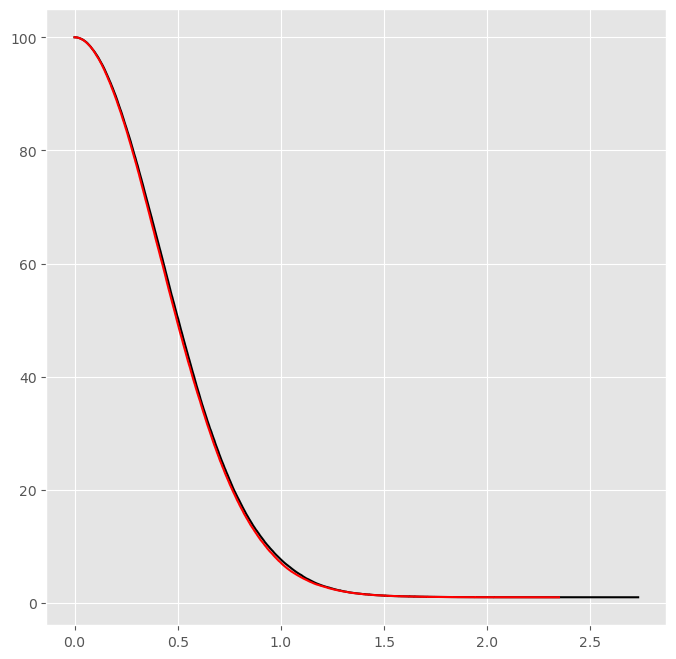

In [50]:
plt.figure(figsize=(8,8))
f_circle.plot(color="black")
f_square.plot(color="red")

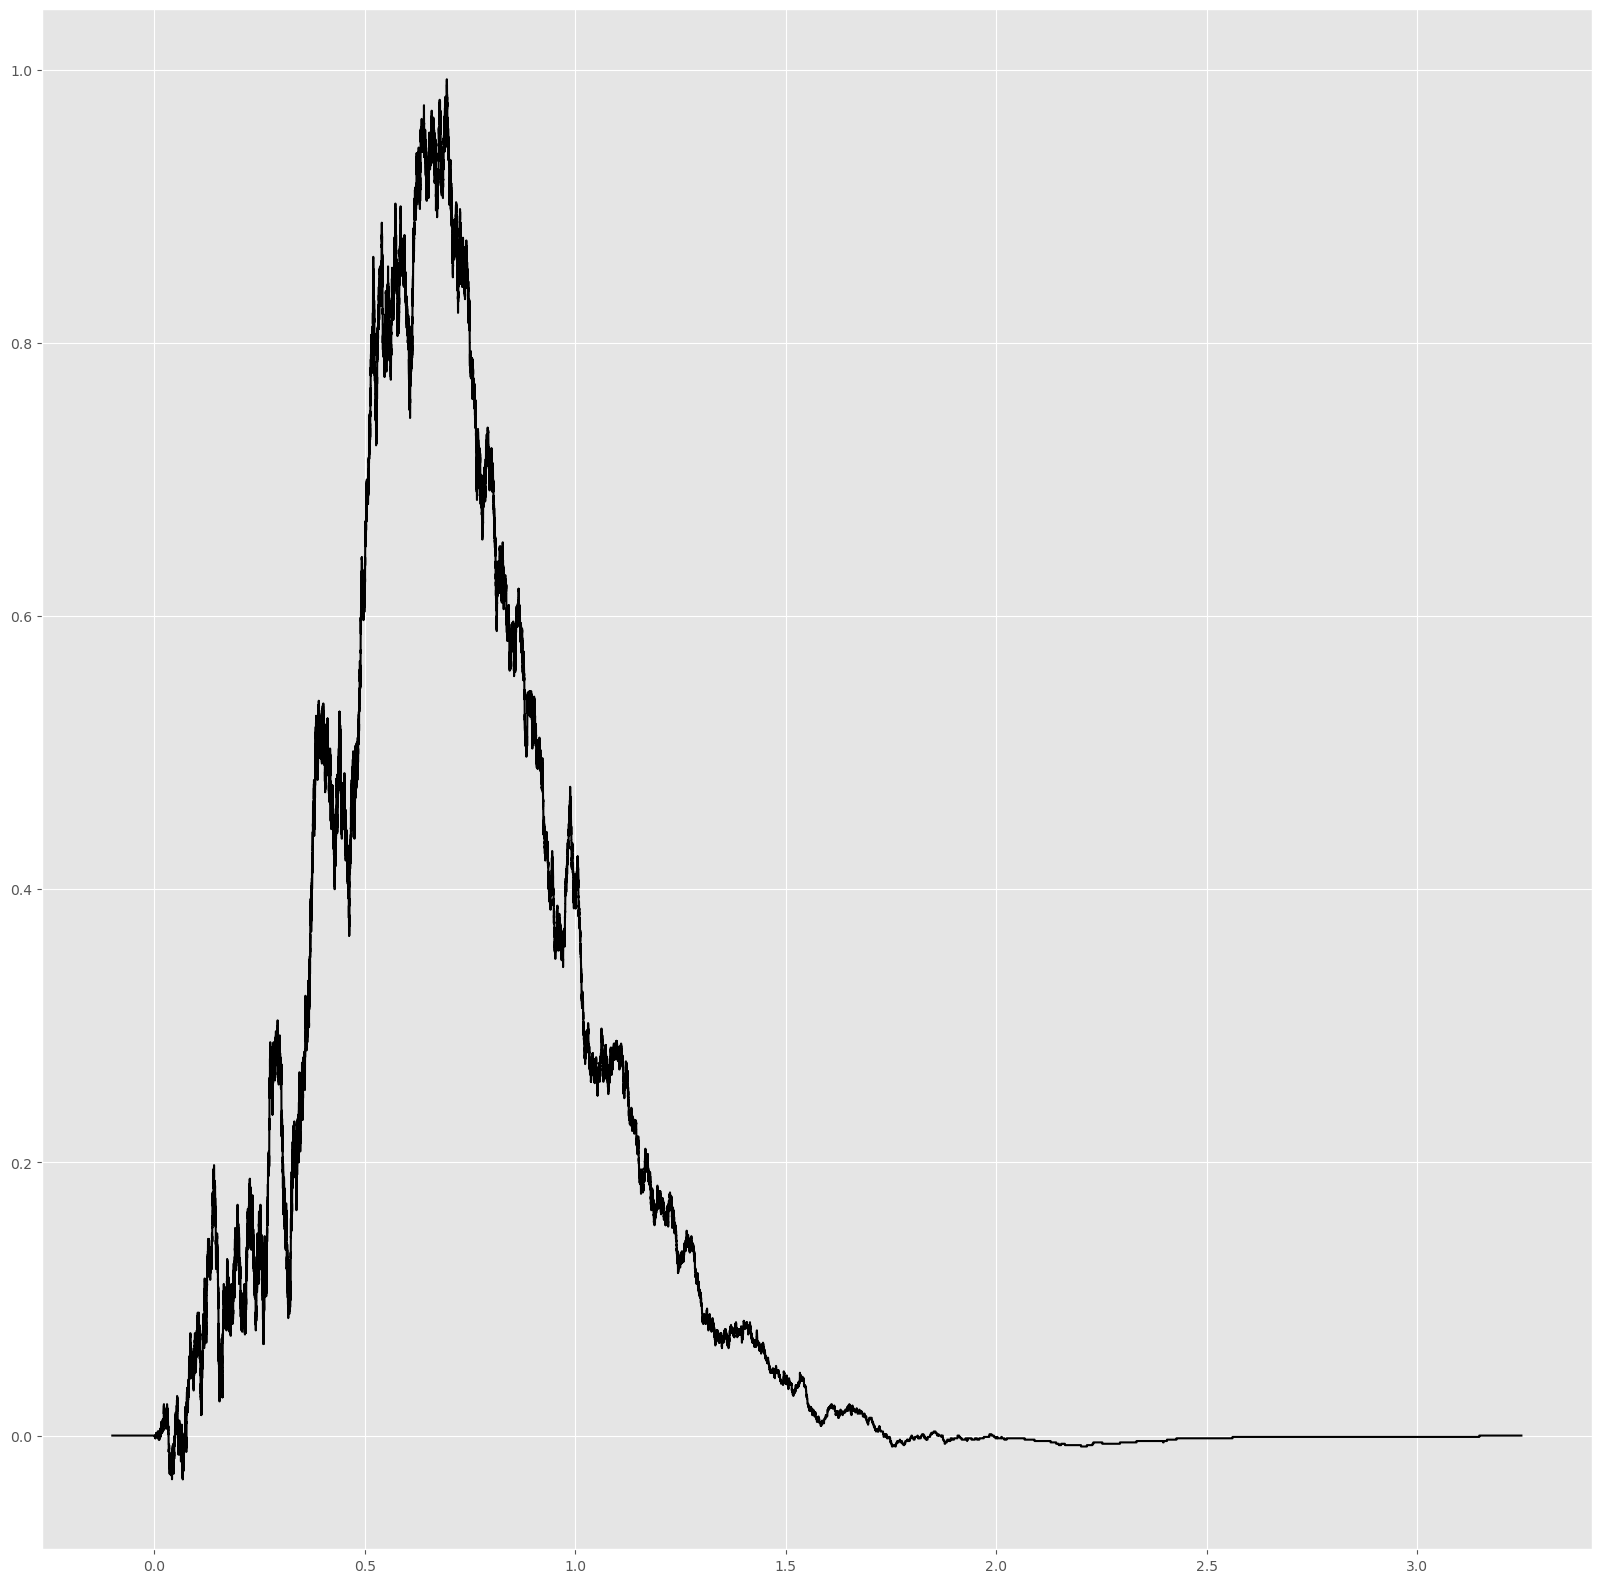

In [38]:
plt.figure(figsize=(20,20))
(f_circle-f_square).plot(color="black")

In [58]:
cm = "complete"
circle_rep = []
square_rep = []

for j in range(10):
    f_circle = sr.zero_pcnif()
    f_square = sr.zero_pcnif()

    number_tries = 1000
    for i in range(number_tries):
        circle = ge.circle(center,r,number_points, error)
        dist = spatial.distance.pdist(circle, "euclidean")
        link = linkage(dist, cm)
        f_circle += sr.linkage_to_sr(link)
        
        square = ge.closed_path(vertices, number_points, error)
        dist = spatial.distance.pdist(square, "euclidean")
        link = linkage(dist, cm)
        f_square += sr.linkage_to_sr(link)
    
    f_circle = f_circle * (1/number_tries) 
    f_square = f_square * (1/number_tries) 
    circle_rep.append(f_circle)
    square_rep.append(f_square)

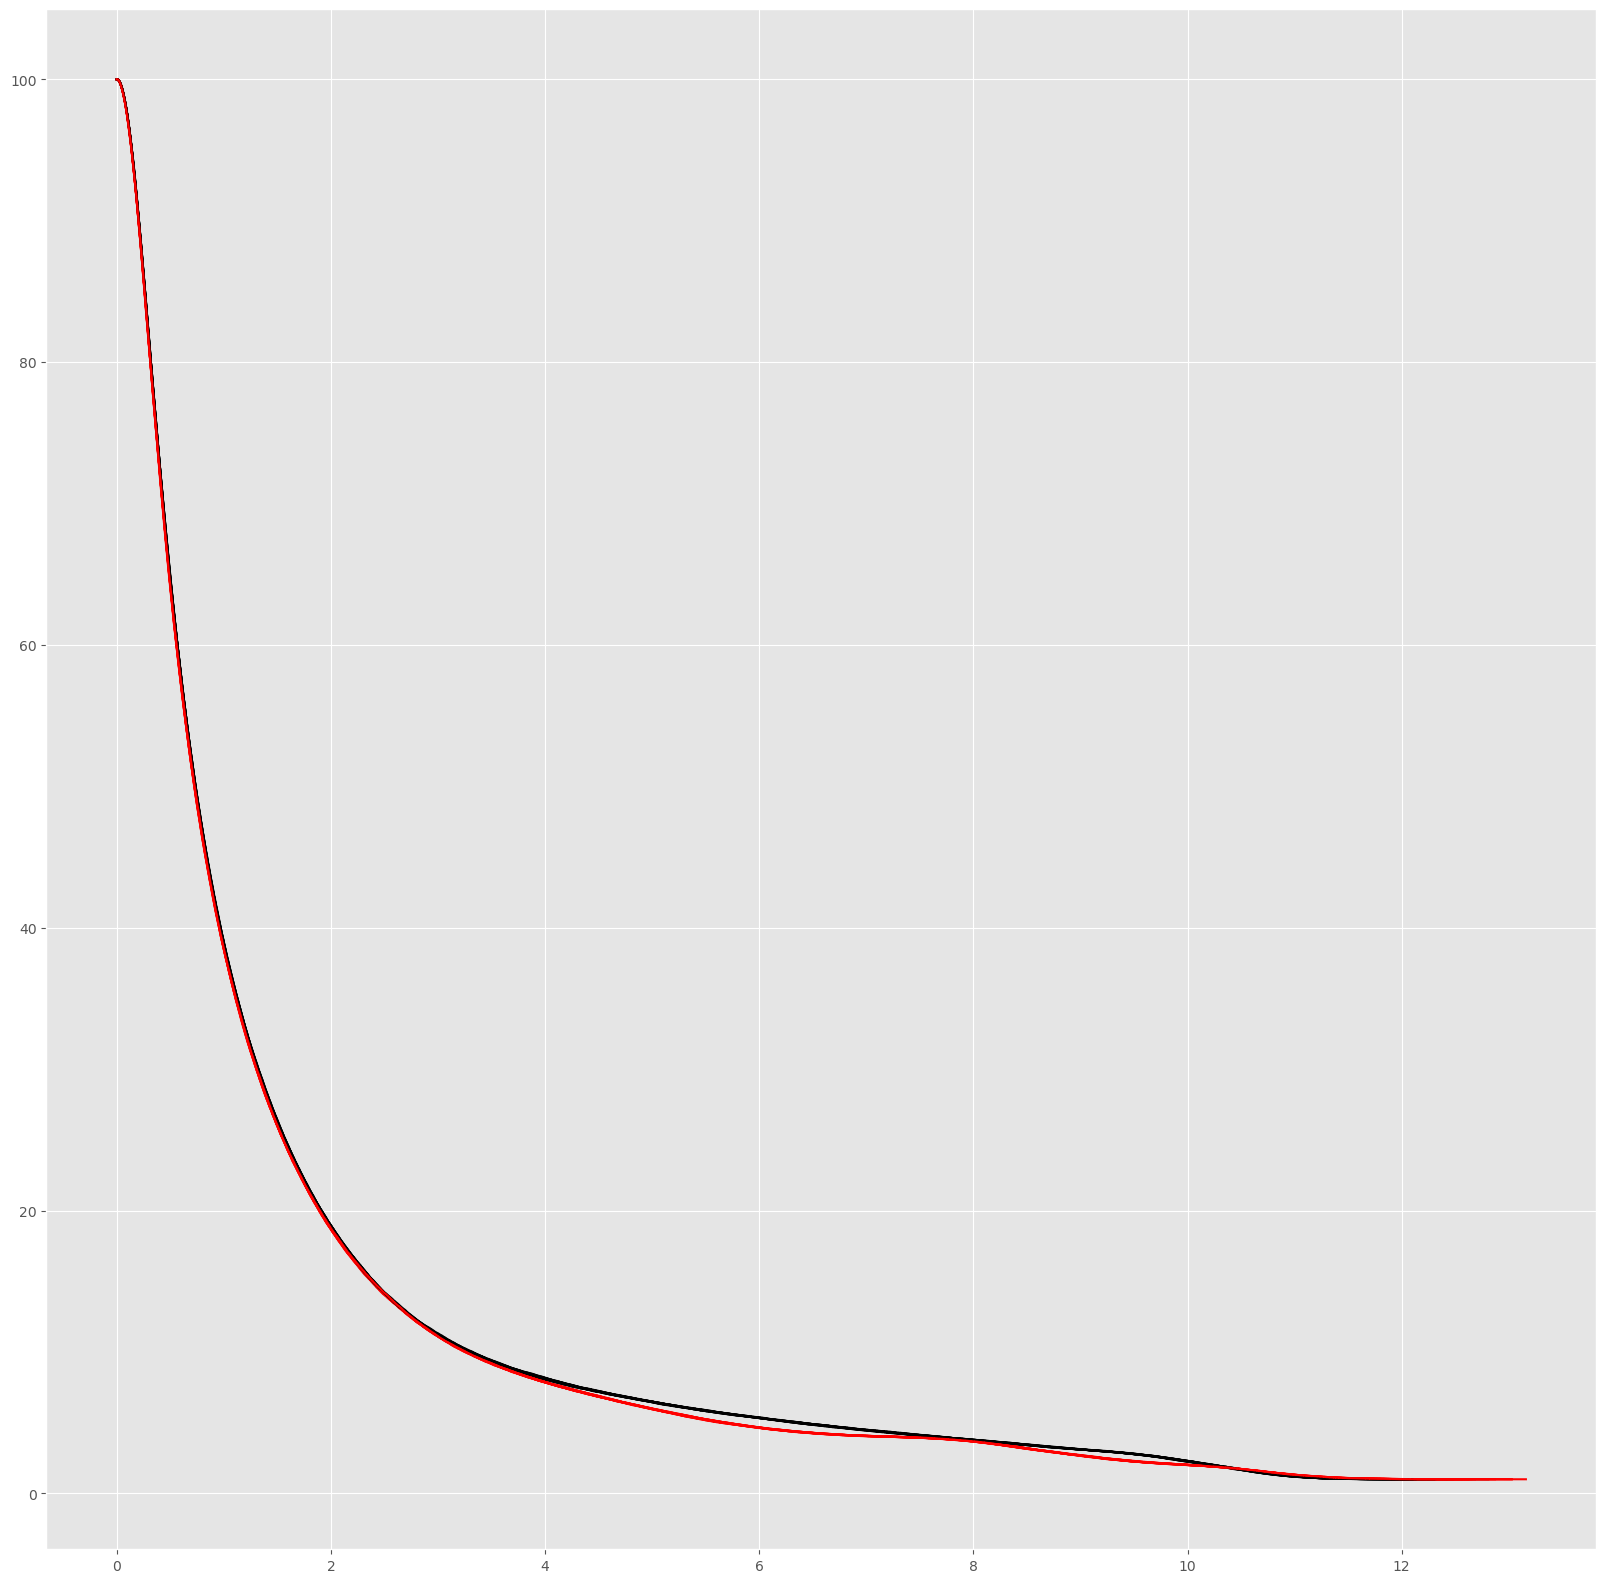

In [60]:
plt.figure(figsize=(20,20))
for j in range(10):
    circle_rep[j].plot(color="black")
    square_rep[j].plot(color="red")

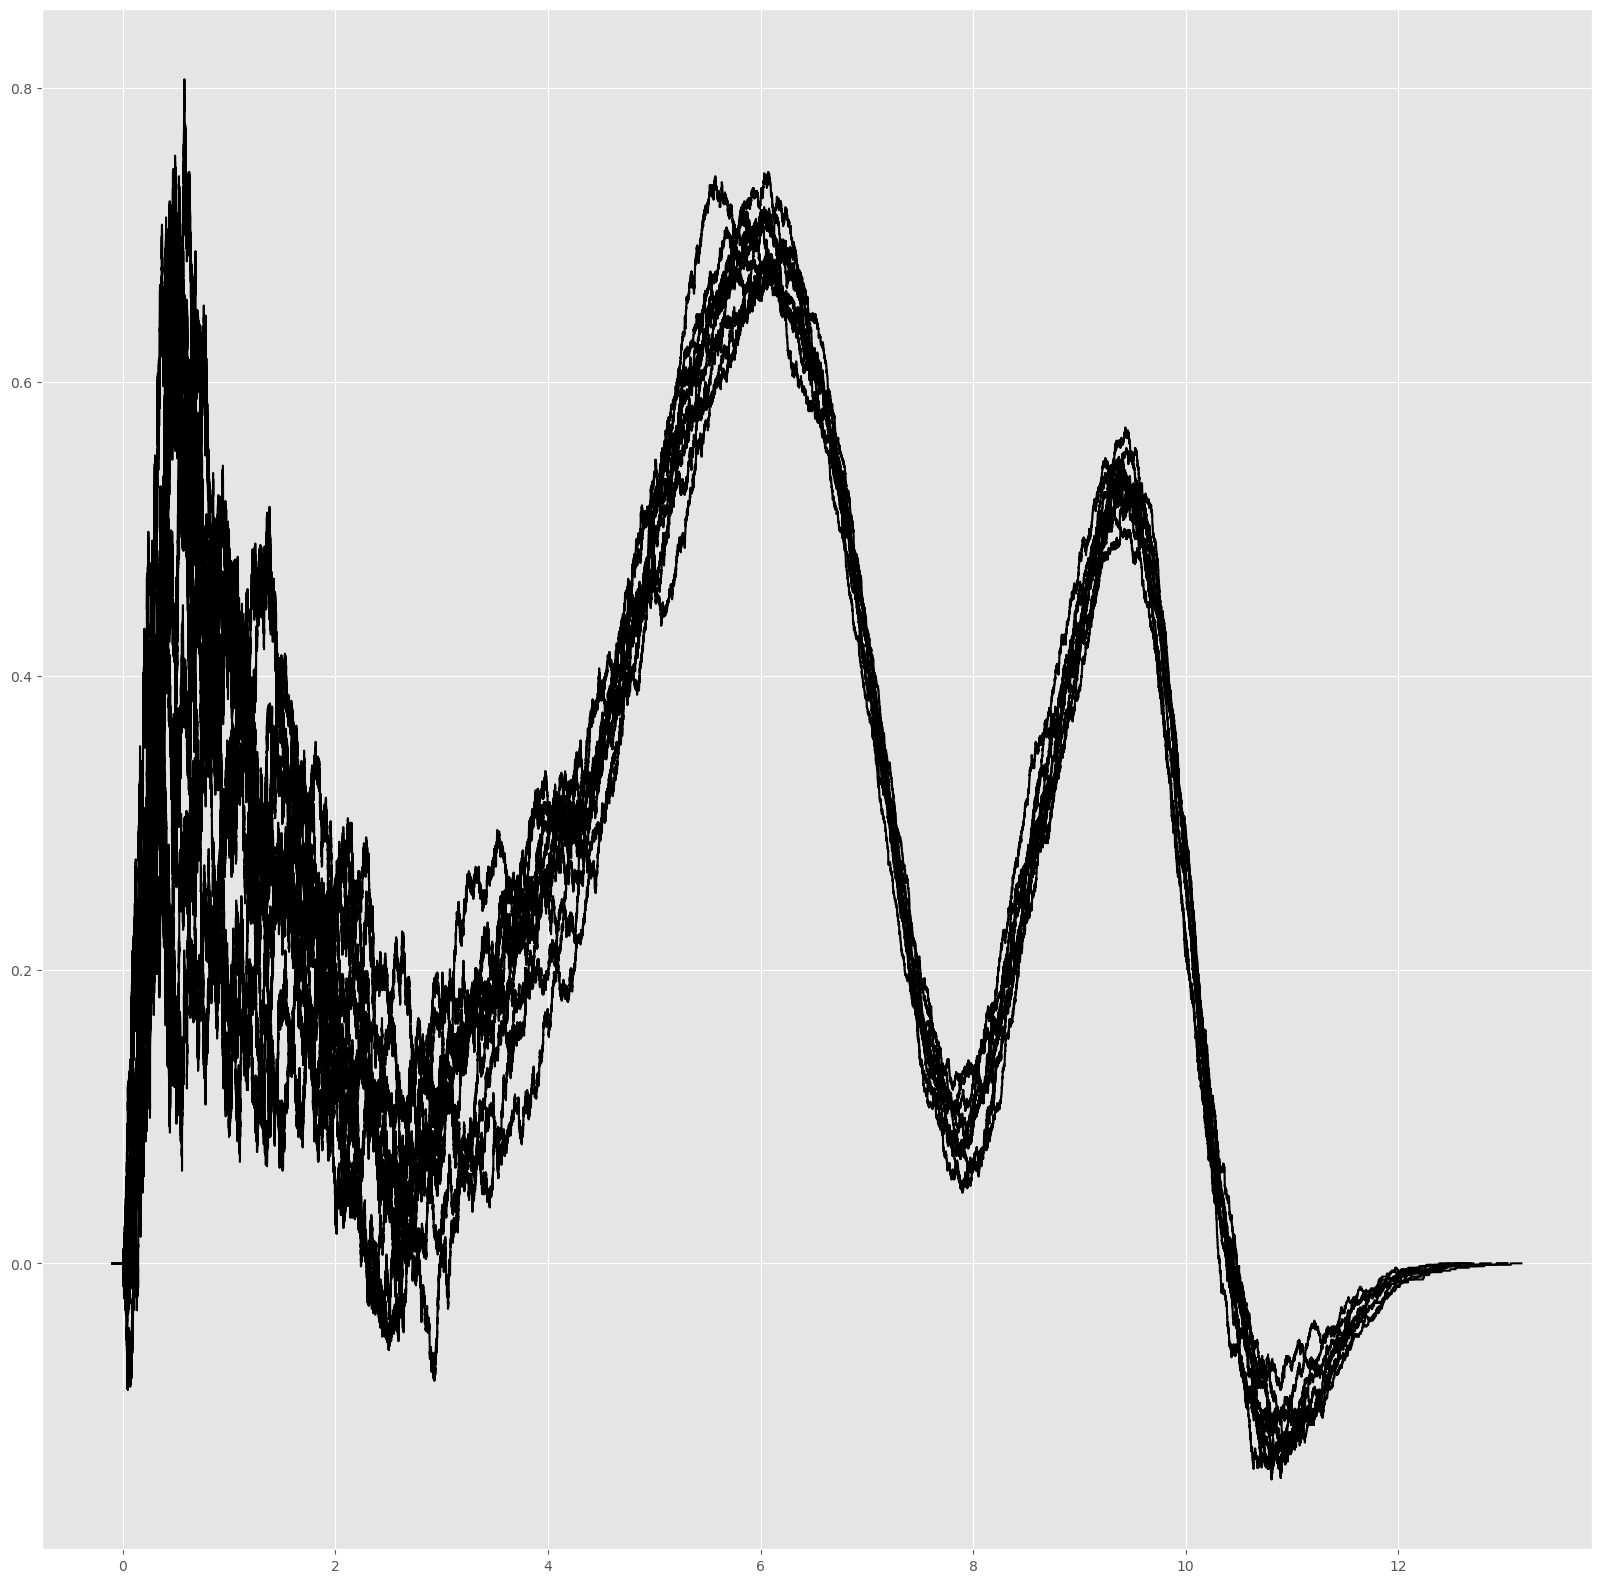

In [62]:
plt.figure(figsize=(20,20))
for i in range(len(circle_rep)):
    f_circle = circle_rep[i]
    f_square = square_rep[i]
    (f_circle-f_square).plot(color="black")

In [64]:
cm = "single"
circle_rep = []
square_rep = []

for j in range(10):
    f_circle = sr.zero_pcnif()
    f_square = sr.zero_pcnif()

    number_tries = 1000
    for i in range(number_tries):
        circle = ge.circle(center,r,number_points, error)
        dist = spatial.distance.pdist(circle, "euclidean")
        link = linkage(dist, cm)
        f_circle += sr.linkage_to_sr(link)
        
        square = ge.closed_path(vertices, number_points, error)
        dist = spatial.distance.pdist(square, "euclidean")
        link = linkage(dist, cm)
        f_square += sr.linkage_to_sr(link)
    
    f_circle = f_circle * (1/number_tries) 
    f_square = f_square * (1/number_tries) 
    circle_rep.append(f_circle)
    square_rep.append(f_square)

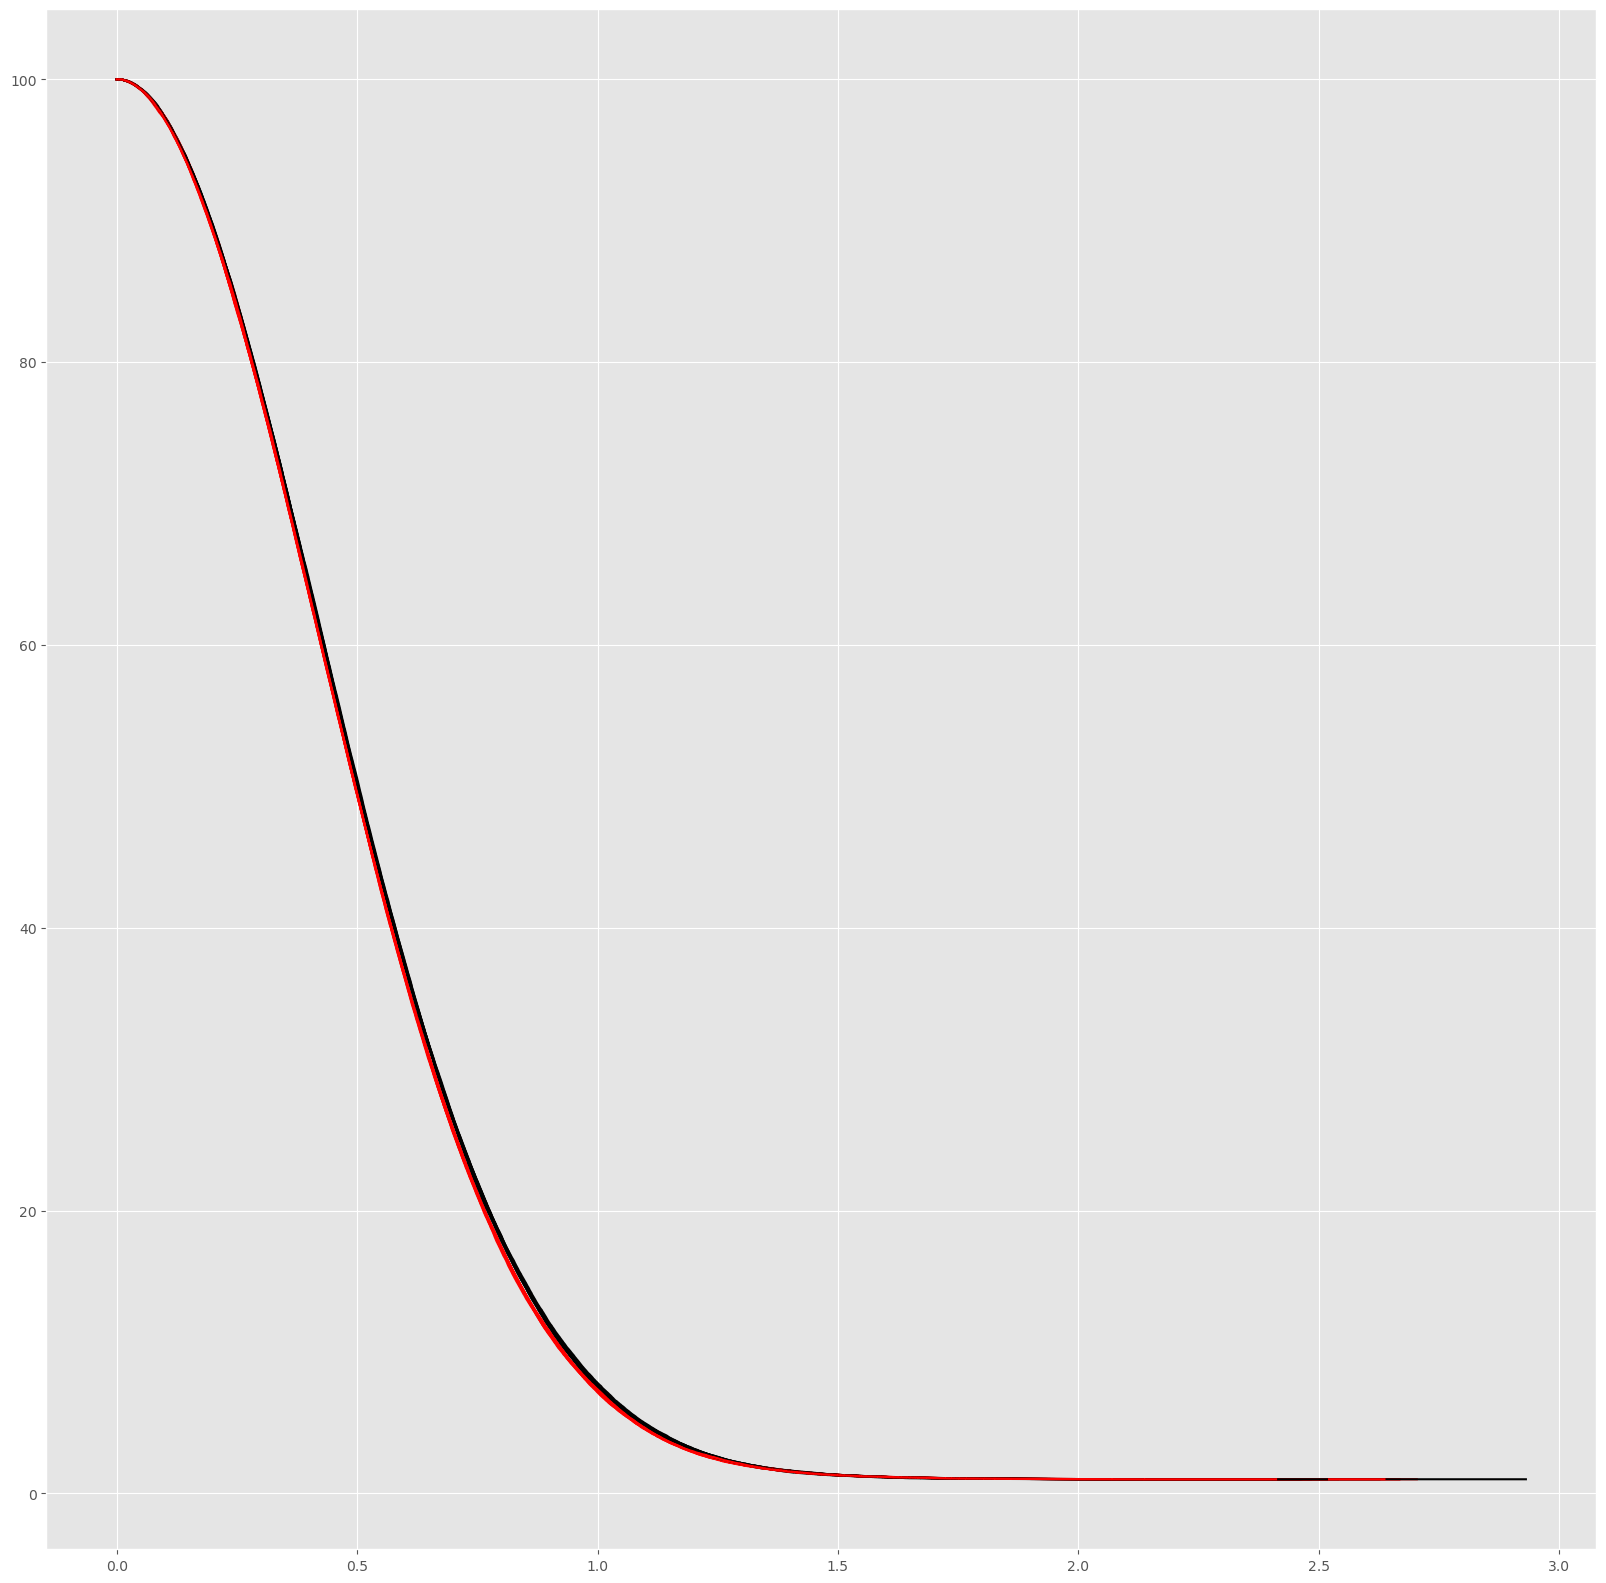

In [66]:
plt.figure(figsize=(20,20))
for j in range(10):
    circle_rep[j].plot(color="black")
    square_rep[j].plot(color="red")

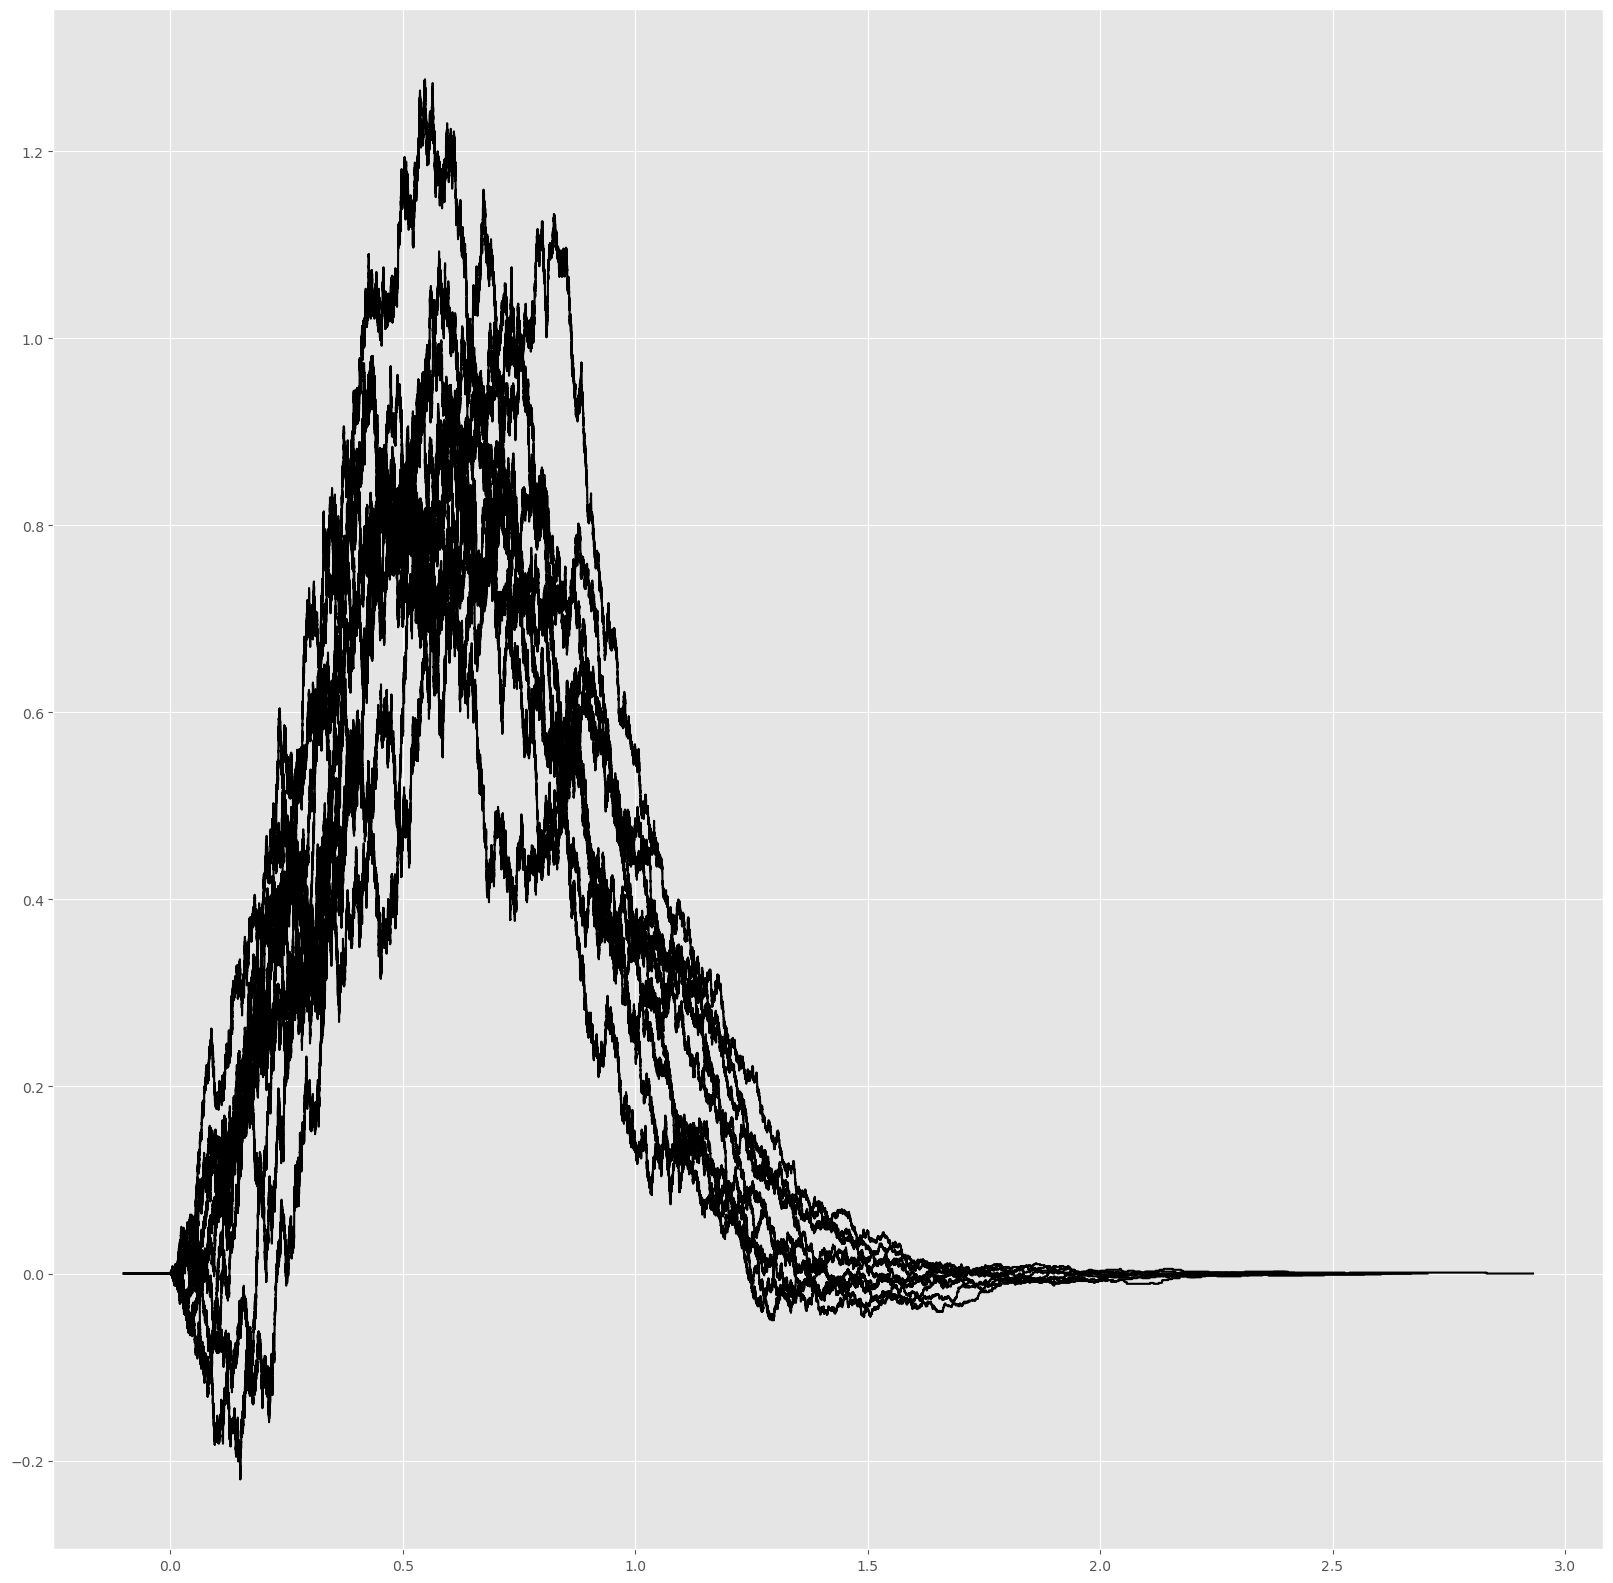

In [68]:
plt.figure(figsize=(20,20))
for i in range(len(circle_rep)):
    f_circle = circle_rep[i]
    f_square = square_rep[i]
    (f_circle-f_square).plot(color="black")

# Plane figures
- The input is given by: $\mathcal{I}=\{X_d\}_{0\leq d<4000},\ \ \ \ \mathcal{D}=\{0,1,\ldots,3999\}$.
- The data $\mathcal{D}$ consists of 4000 integers $\mathcal{D}=\{0,1,\ldots,3999\}$. 
- Each integer $d$ in $\mathcal{D}$ is represented by a subset $X_d\subset \mathbb{R}^2$ of 800 points. 
- 0-999 circle, 1000-1999 rectangle, 2000-2999 triangle, 3000-3999 X

For example:

In [42]:
file = open("Data/plain_figures_data", "rb")
plain_figures_data = pickle.load(file)

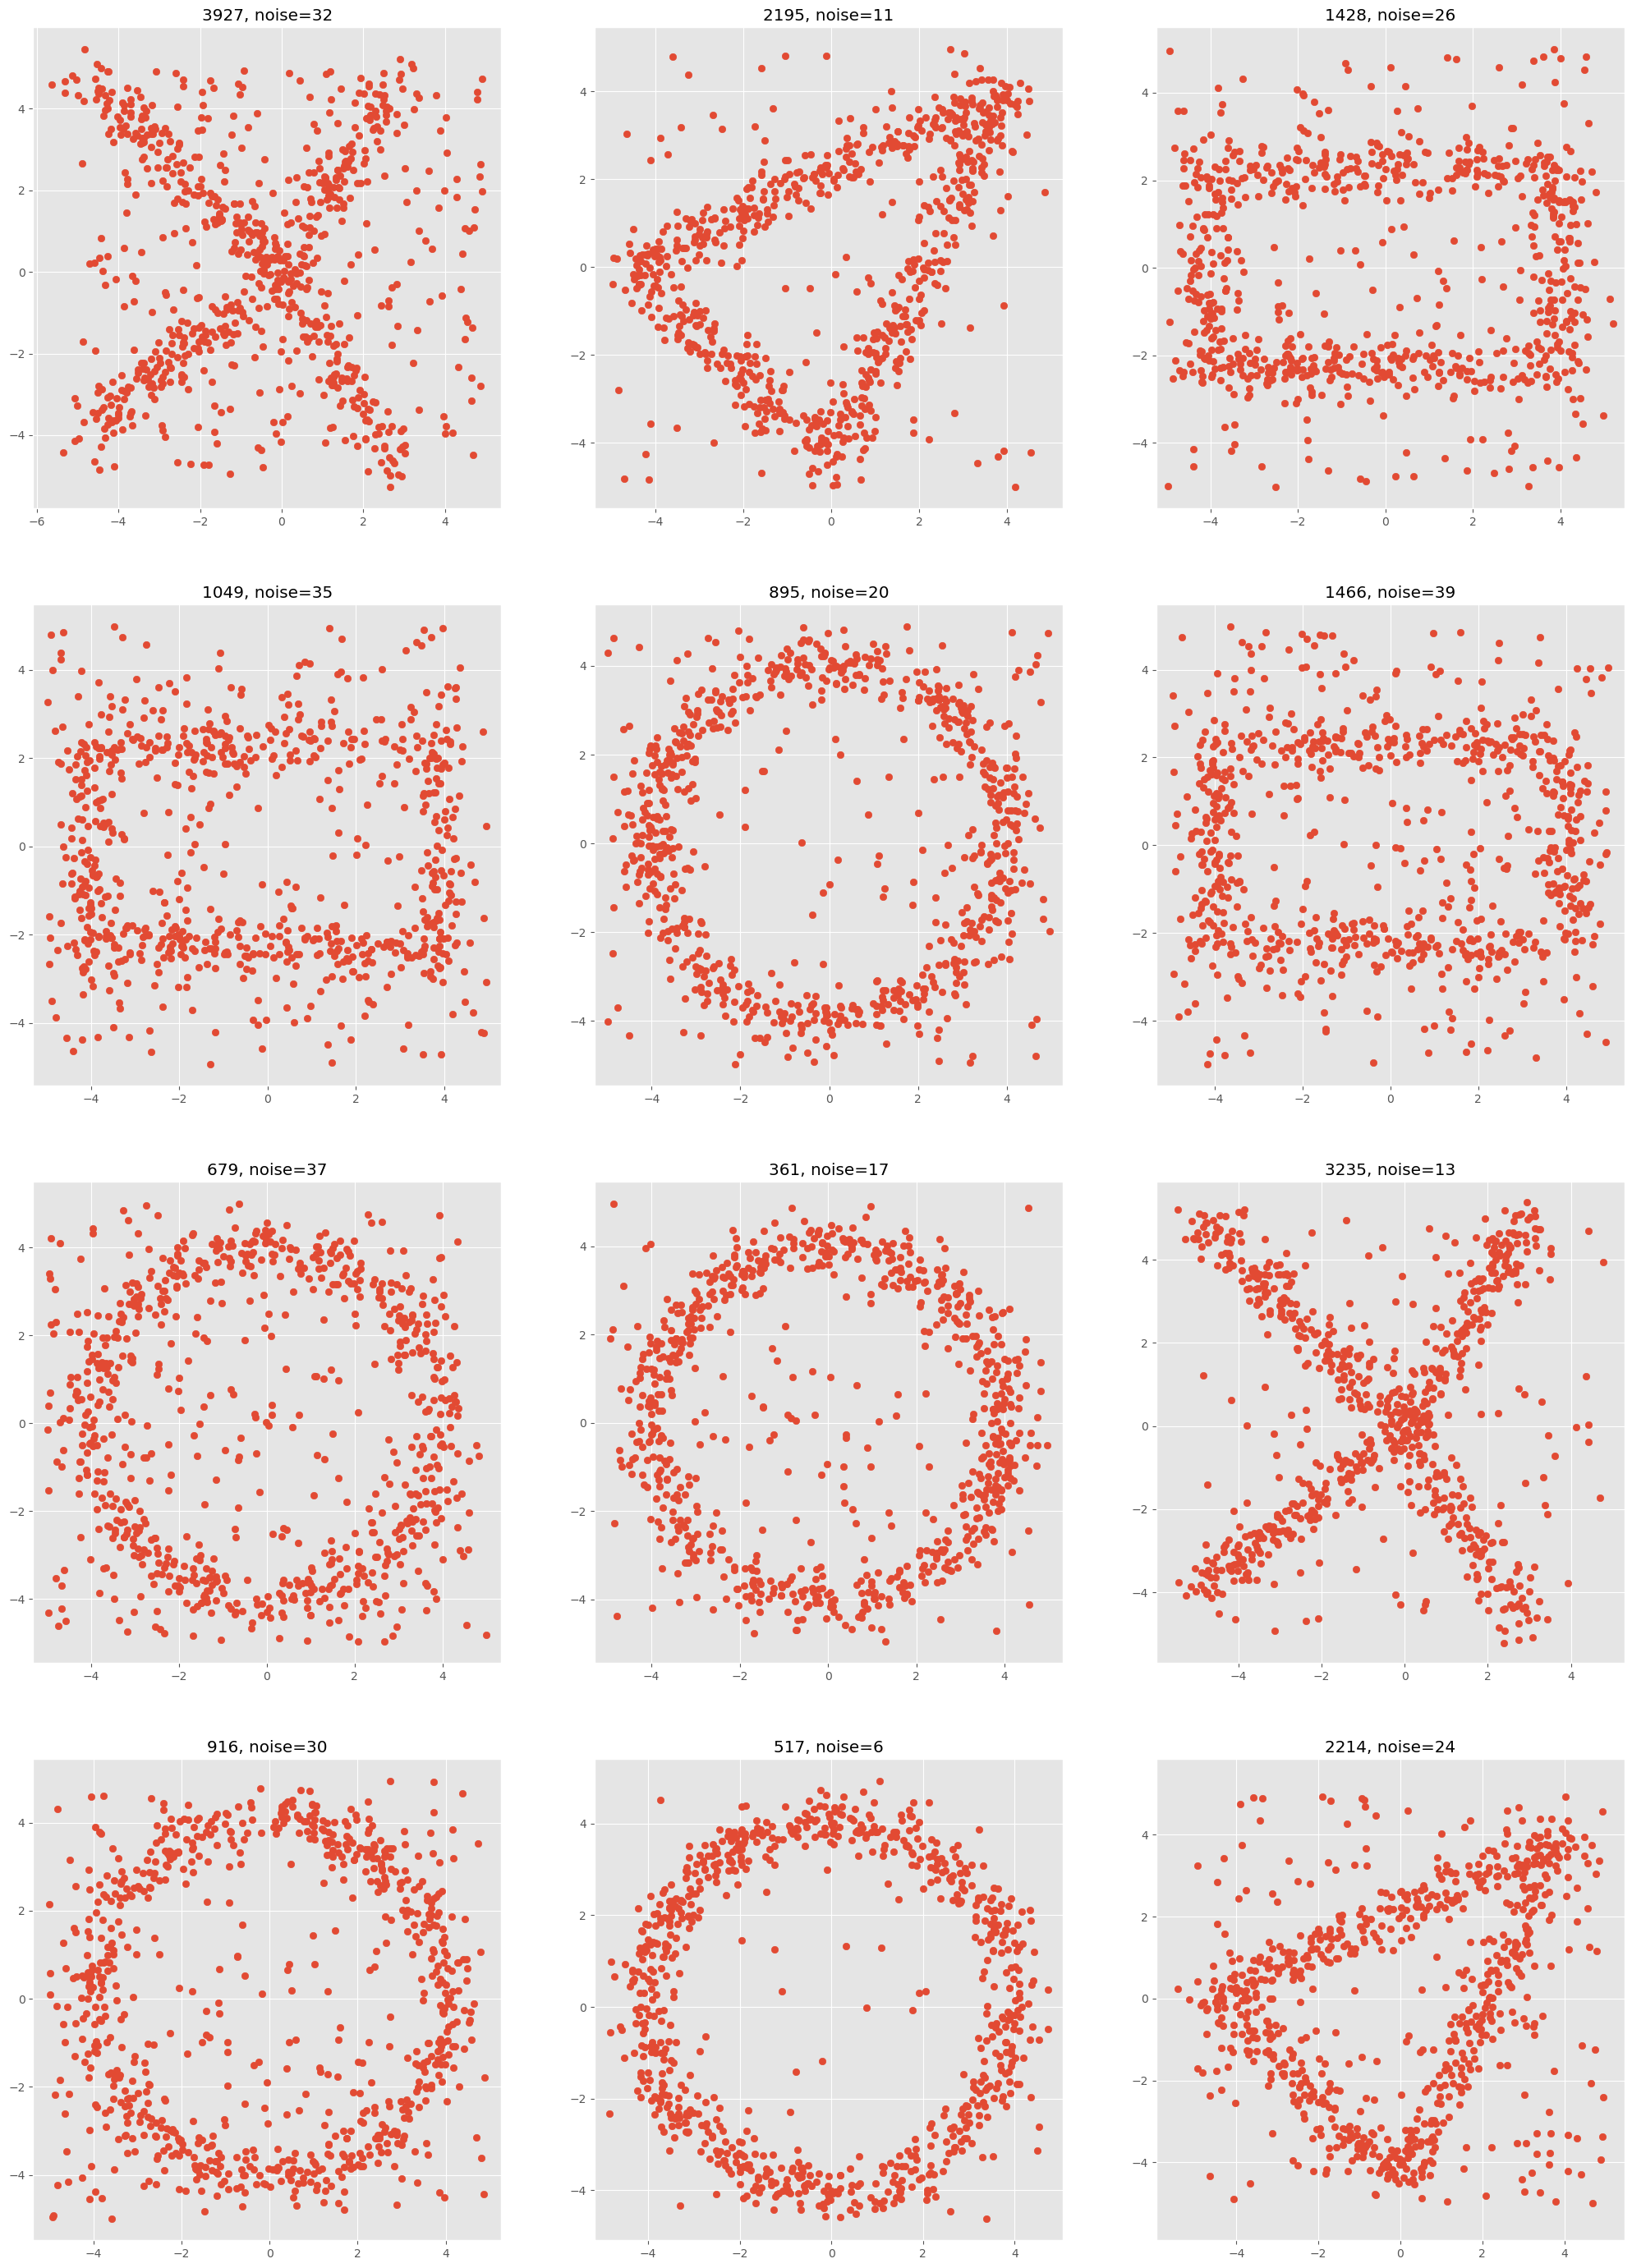

In [59]:
some_data = np.random.choice(4000, 12, replace=False)

plt.figure(figsize=(25, 35))
i=1
for d in some_data:
    ax = plt.subplot(4,3,i)
    bkg_noise = plain_figures_data.at[d,"bkg noise"]
    ax.set_title(str(d)+", "+"noise="+str(bkg_noise))
    plt.axis('equal')
    figure = plain_figures_data.at[d,"figure"]
    plt.scatter(figure[:,0], figure[:,1]) 
    i=i+1

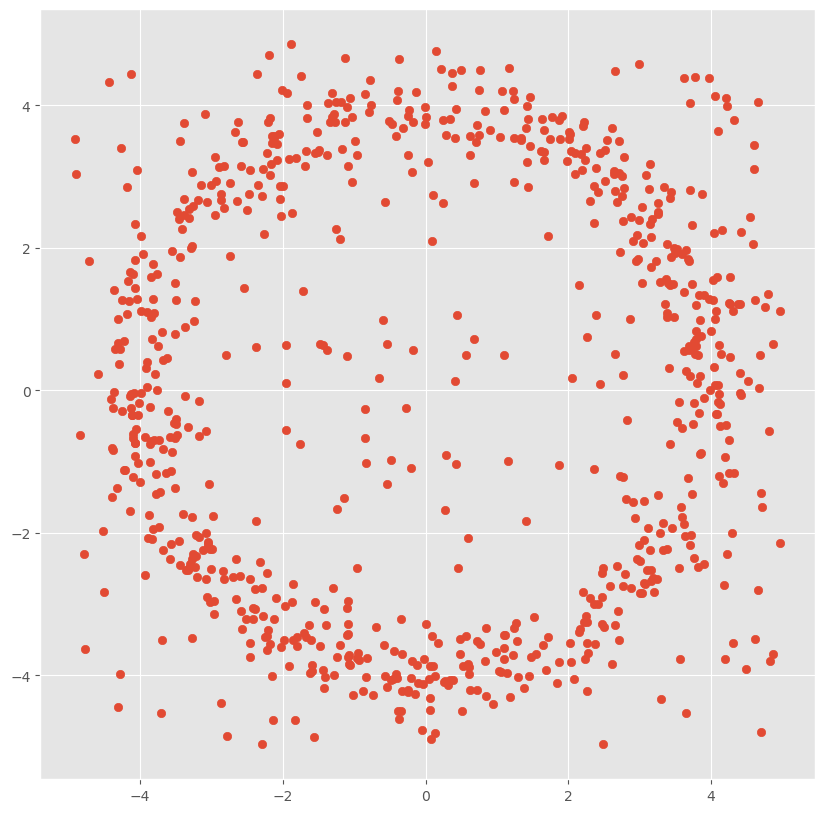

In [43]:
figure = plain_figures_data.at[689,"figure"]
plt.figure(figsize=(10,10))
plt.axis('equal')
plt.scatter(figure[:,0], figure[:,1]) 


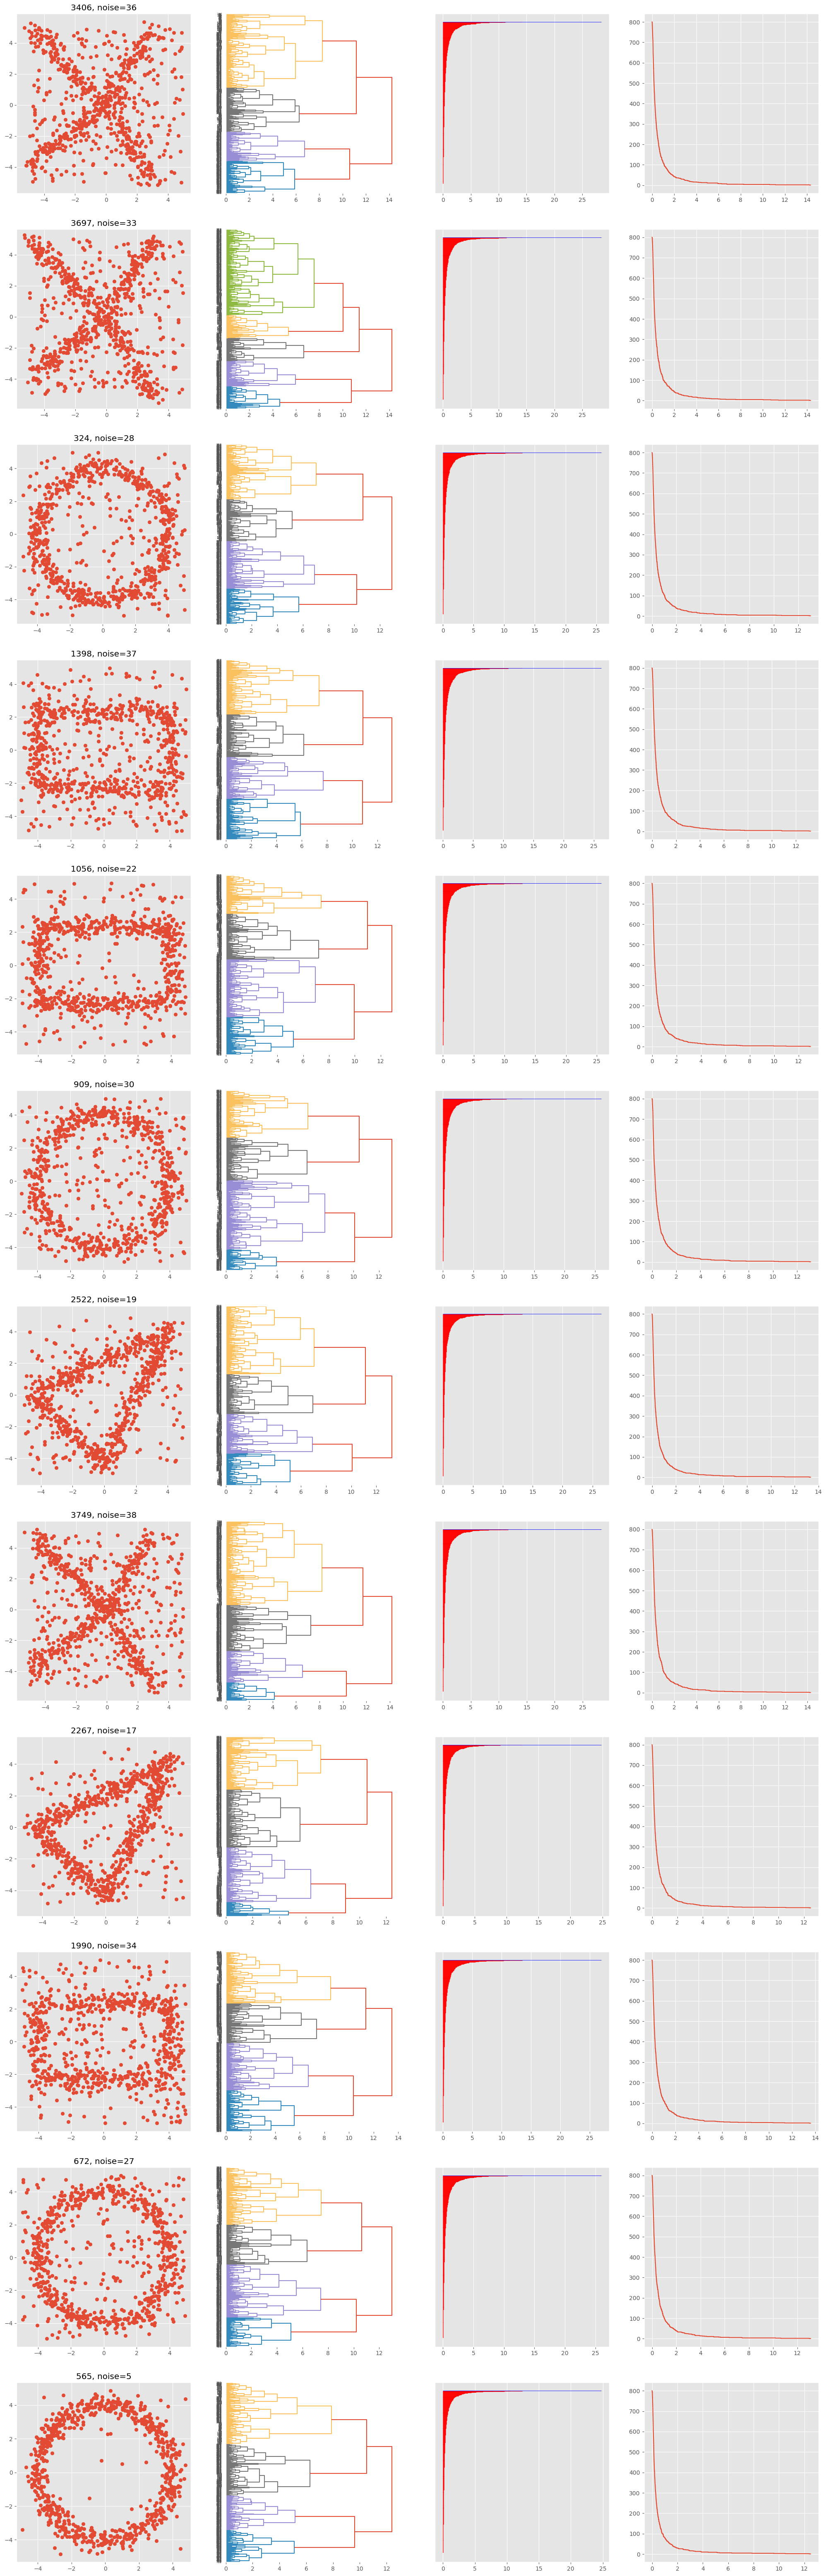

In [68]:
some_data = np.random.choice(4000, 12, replace=False)
cm = "complete"

plt.figure(figsize=(25, 80))
i=1
for d in some_data:
    ax = plt.subplot(12,4,i)
    bkg_noise = plain_figures_data.at[d,"bkg noise"]
    ax.set_title(str(d)+", "+"noise="+str(bkg_noise))
    plt.axis('equal')
    
    figure = plain_figures_data.at[d,"figure"]
    plt.scatter(figure[:,0], figure[:,1]) 
    i += 1
    
    ax = plt.subplot(12,4,i)
    dist = spatial.distance.pdist(figure, "euclidean")
    l =  linkage(dist, cm)
    dendrogram(l, orientation='right')
    i += 1
    
    ax = plt.subplot(12,4,i)
    b = sr.linkage_to_bc(l)
    b.plot()
    i += +1
    
    ax = plt.subplot(12,4,i)
    f = b.stable_rank()
    f.plot()
    i += +1

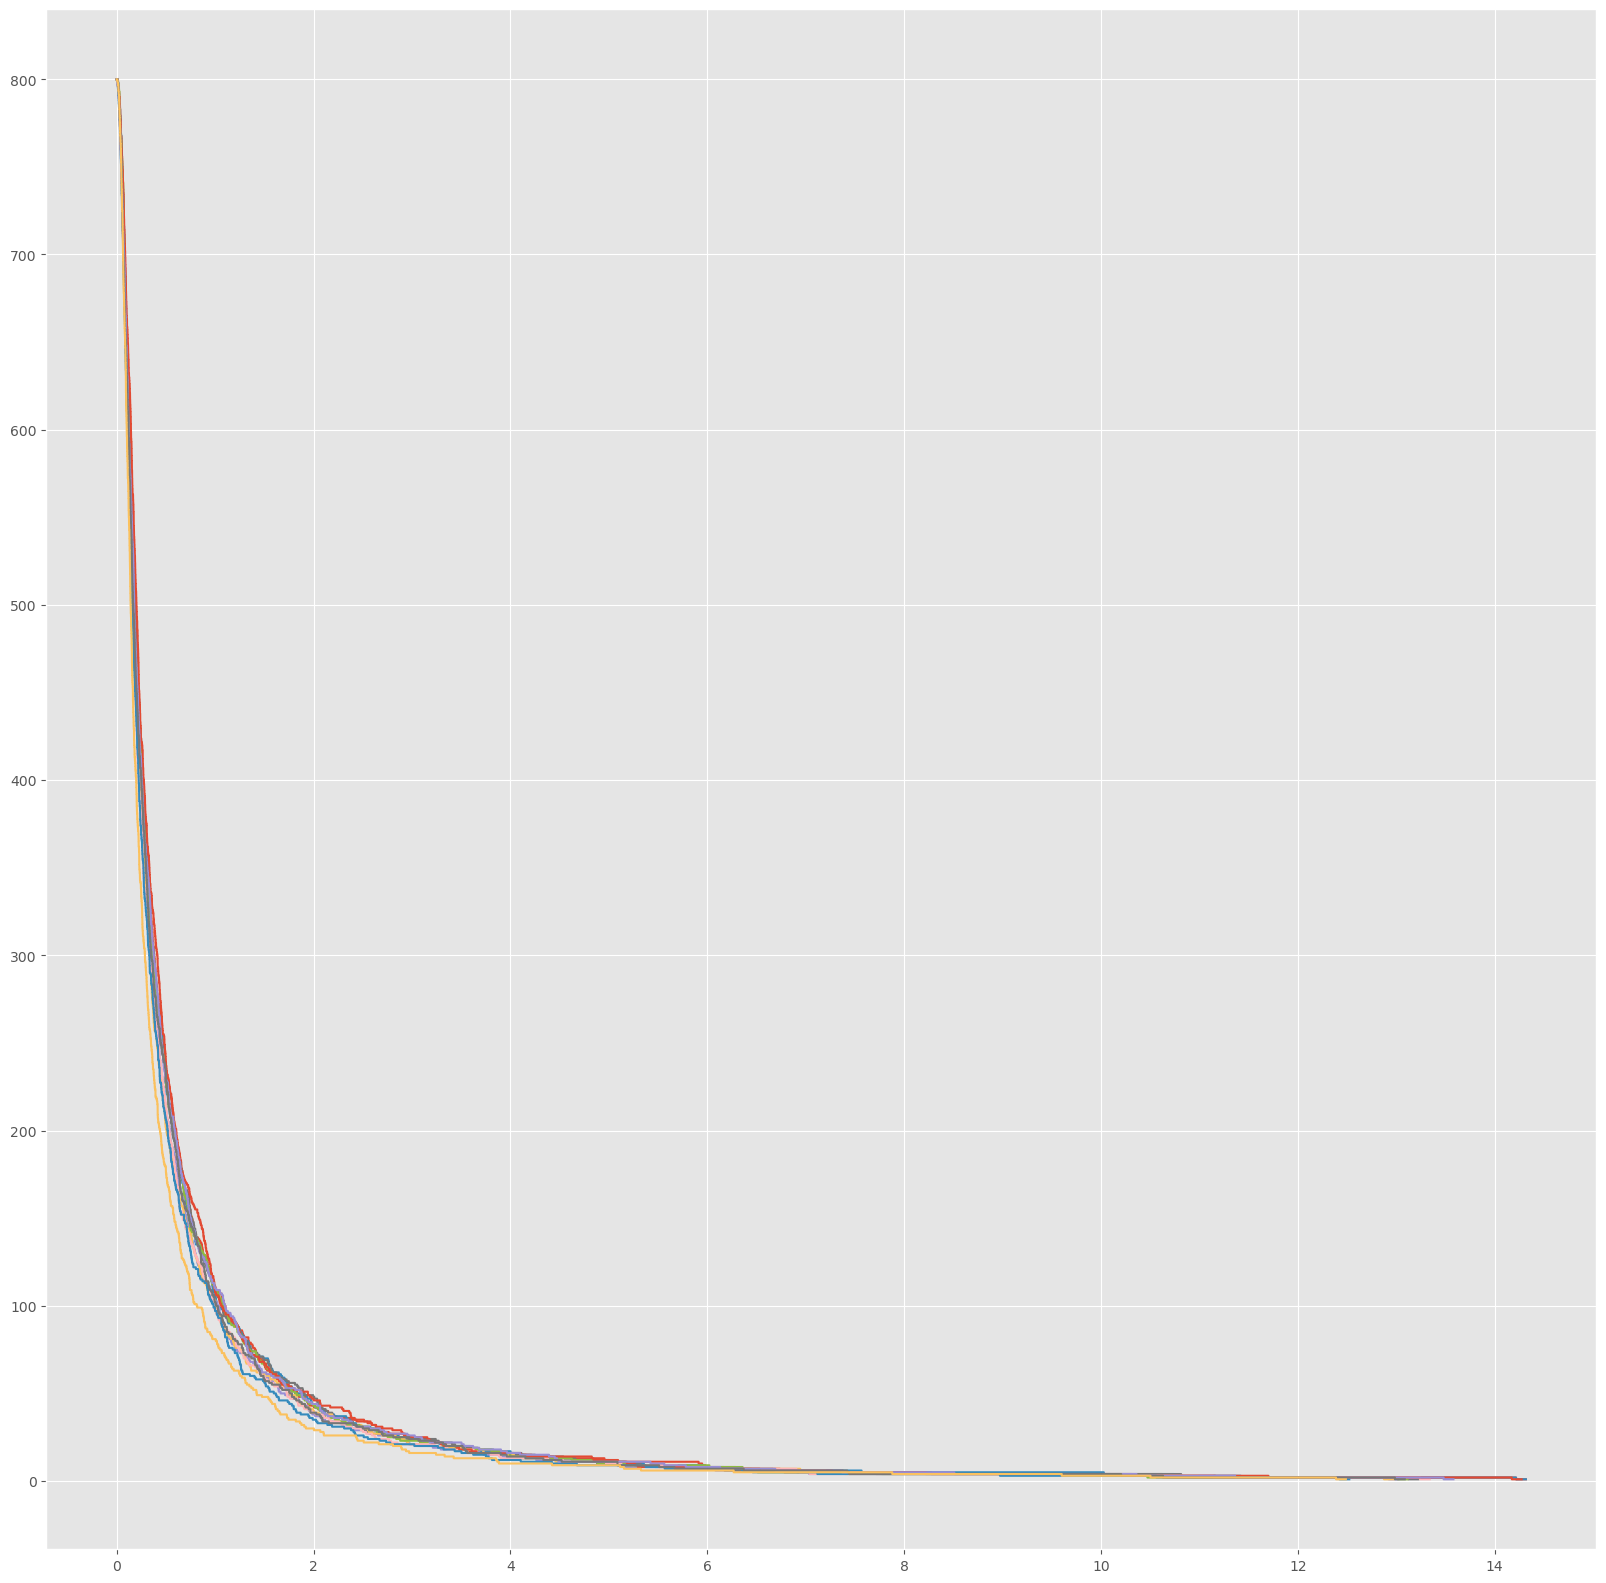

In [71]:
plt.figure(figsize=(20,20))
for d in some_data:
    figure = plain_figures_data.at[d,"figure"]
    dist = spatial.distance.pdist(figure, "euclidean")
    l =  linkage(dist, cm)
    b = sr.linkage_to_bc(l)
    f = b.stable_rank()
    f.plot()
    

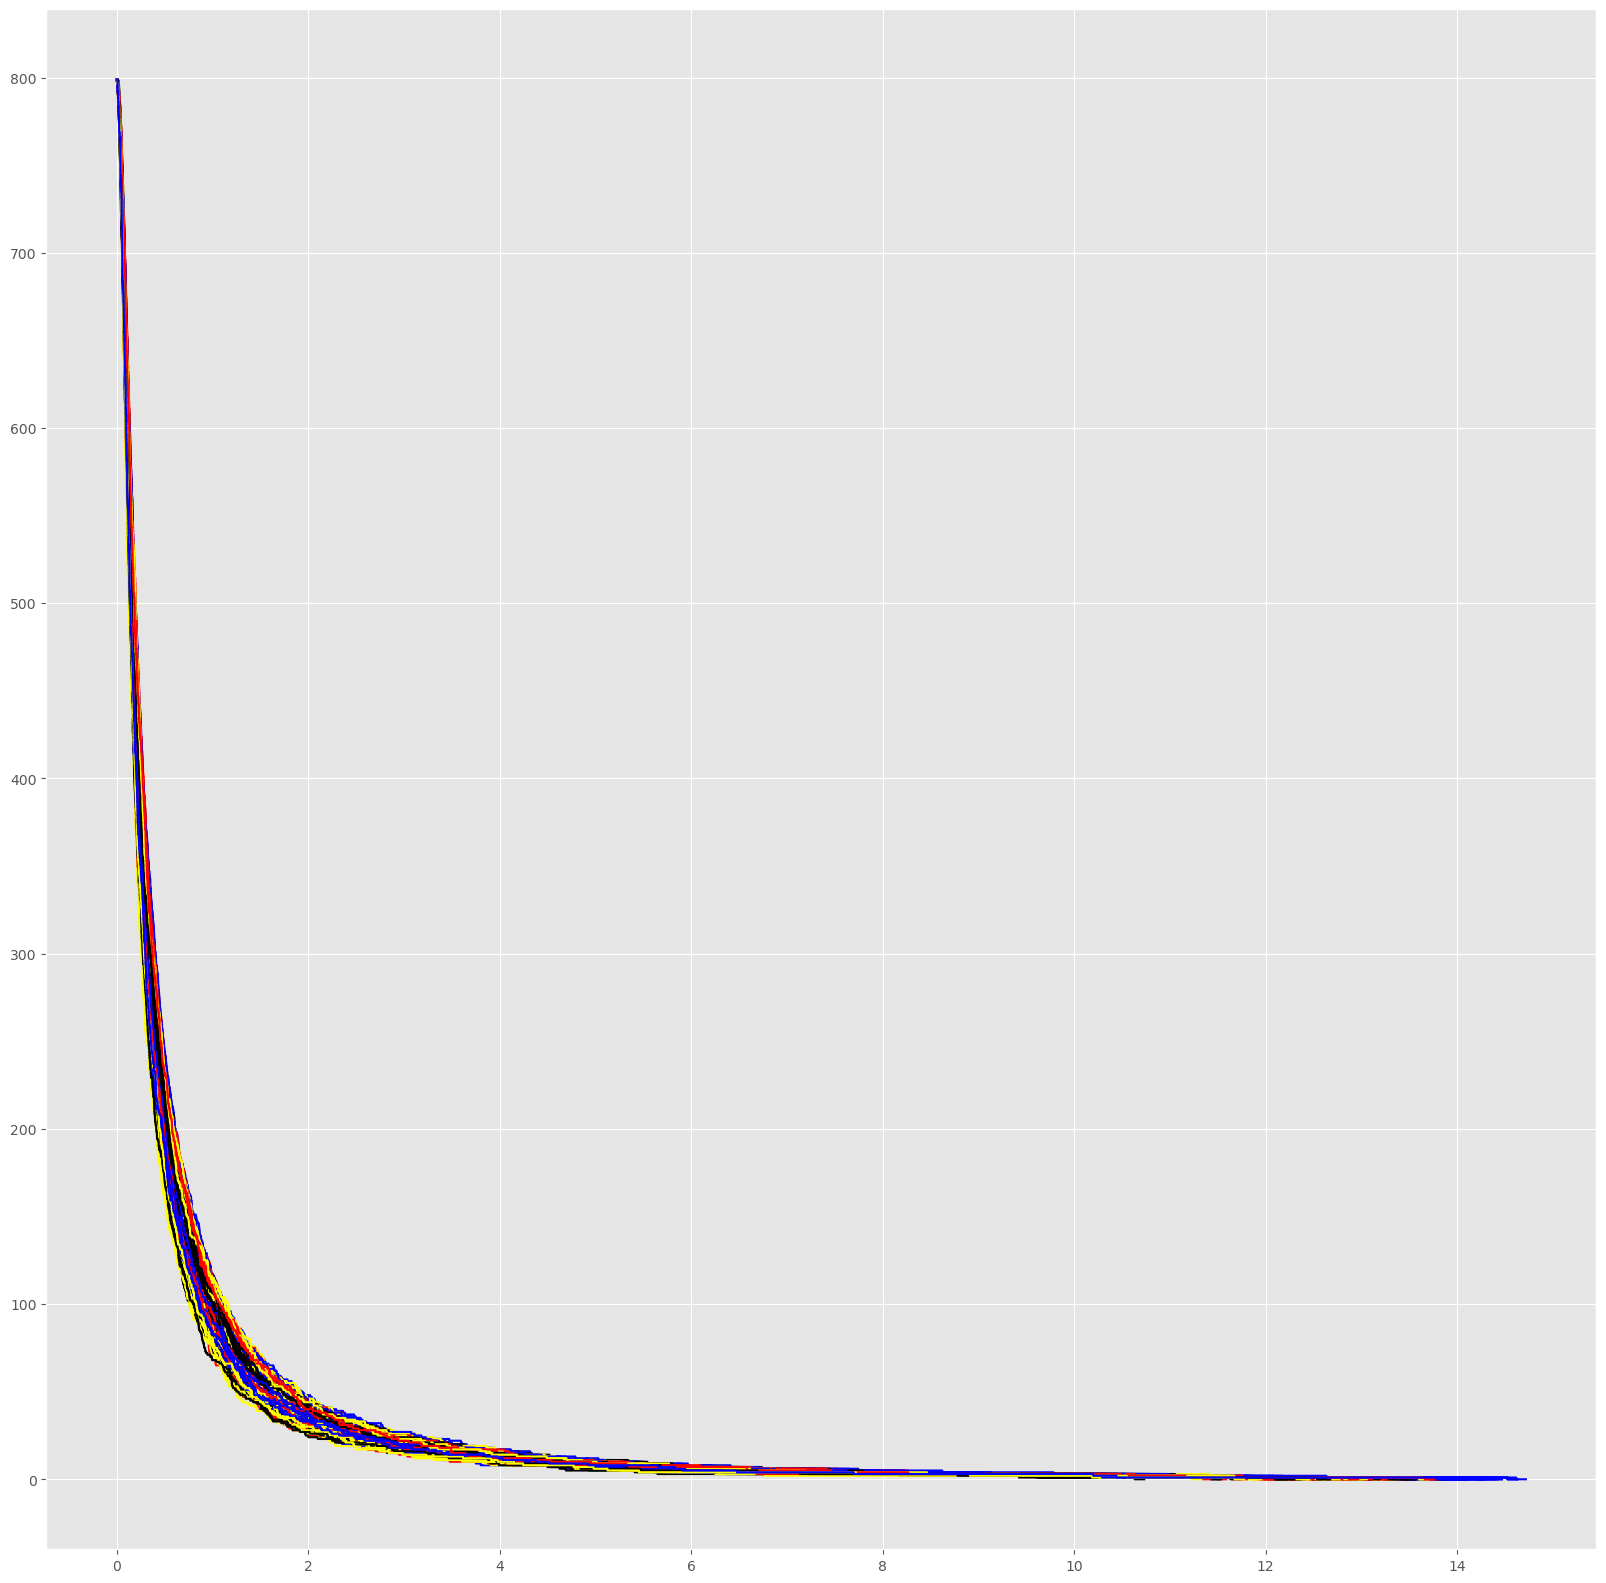

In [74]:

plt.figure(figsize=(20,20))

for i in range(0, 100):
    figure = plain_figures_data.at[i,"figure"]
    dist = pdist(figure, "euclidean")
    D = sr.Distance(squareform(dist))
    f = D.get_h0sr(clustering_method=cm)
    f.plot(color="red")
    
    figure = plain_figures_data.at[1000 + i,"figure"]
    dist = pdist(figure, "euclidean")
    D = sr.Distance(squareform(dist))
    g = D.get_h0sr(clustering_method=cm)
    g.plot(color="black")
    
    figure = plain_figures_data.at[2000 + i,"figure"]
    dist = pdist(figure, "euclidean")
    D = sr.Distance(squareform(dist))
    g = D.get_h0sr(clustering_method=cm)
    g.plot(color="yellow")
    
    figure = plain_figures_data.at[3000 + i,"figure"]
    dist = pdist(figure, "euclidean")
    D = sr.Distance(squareform(dist))
    g = D.get_h0sr(clustering_method=cm)
    g.plot(color="blue")


## Subsampling

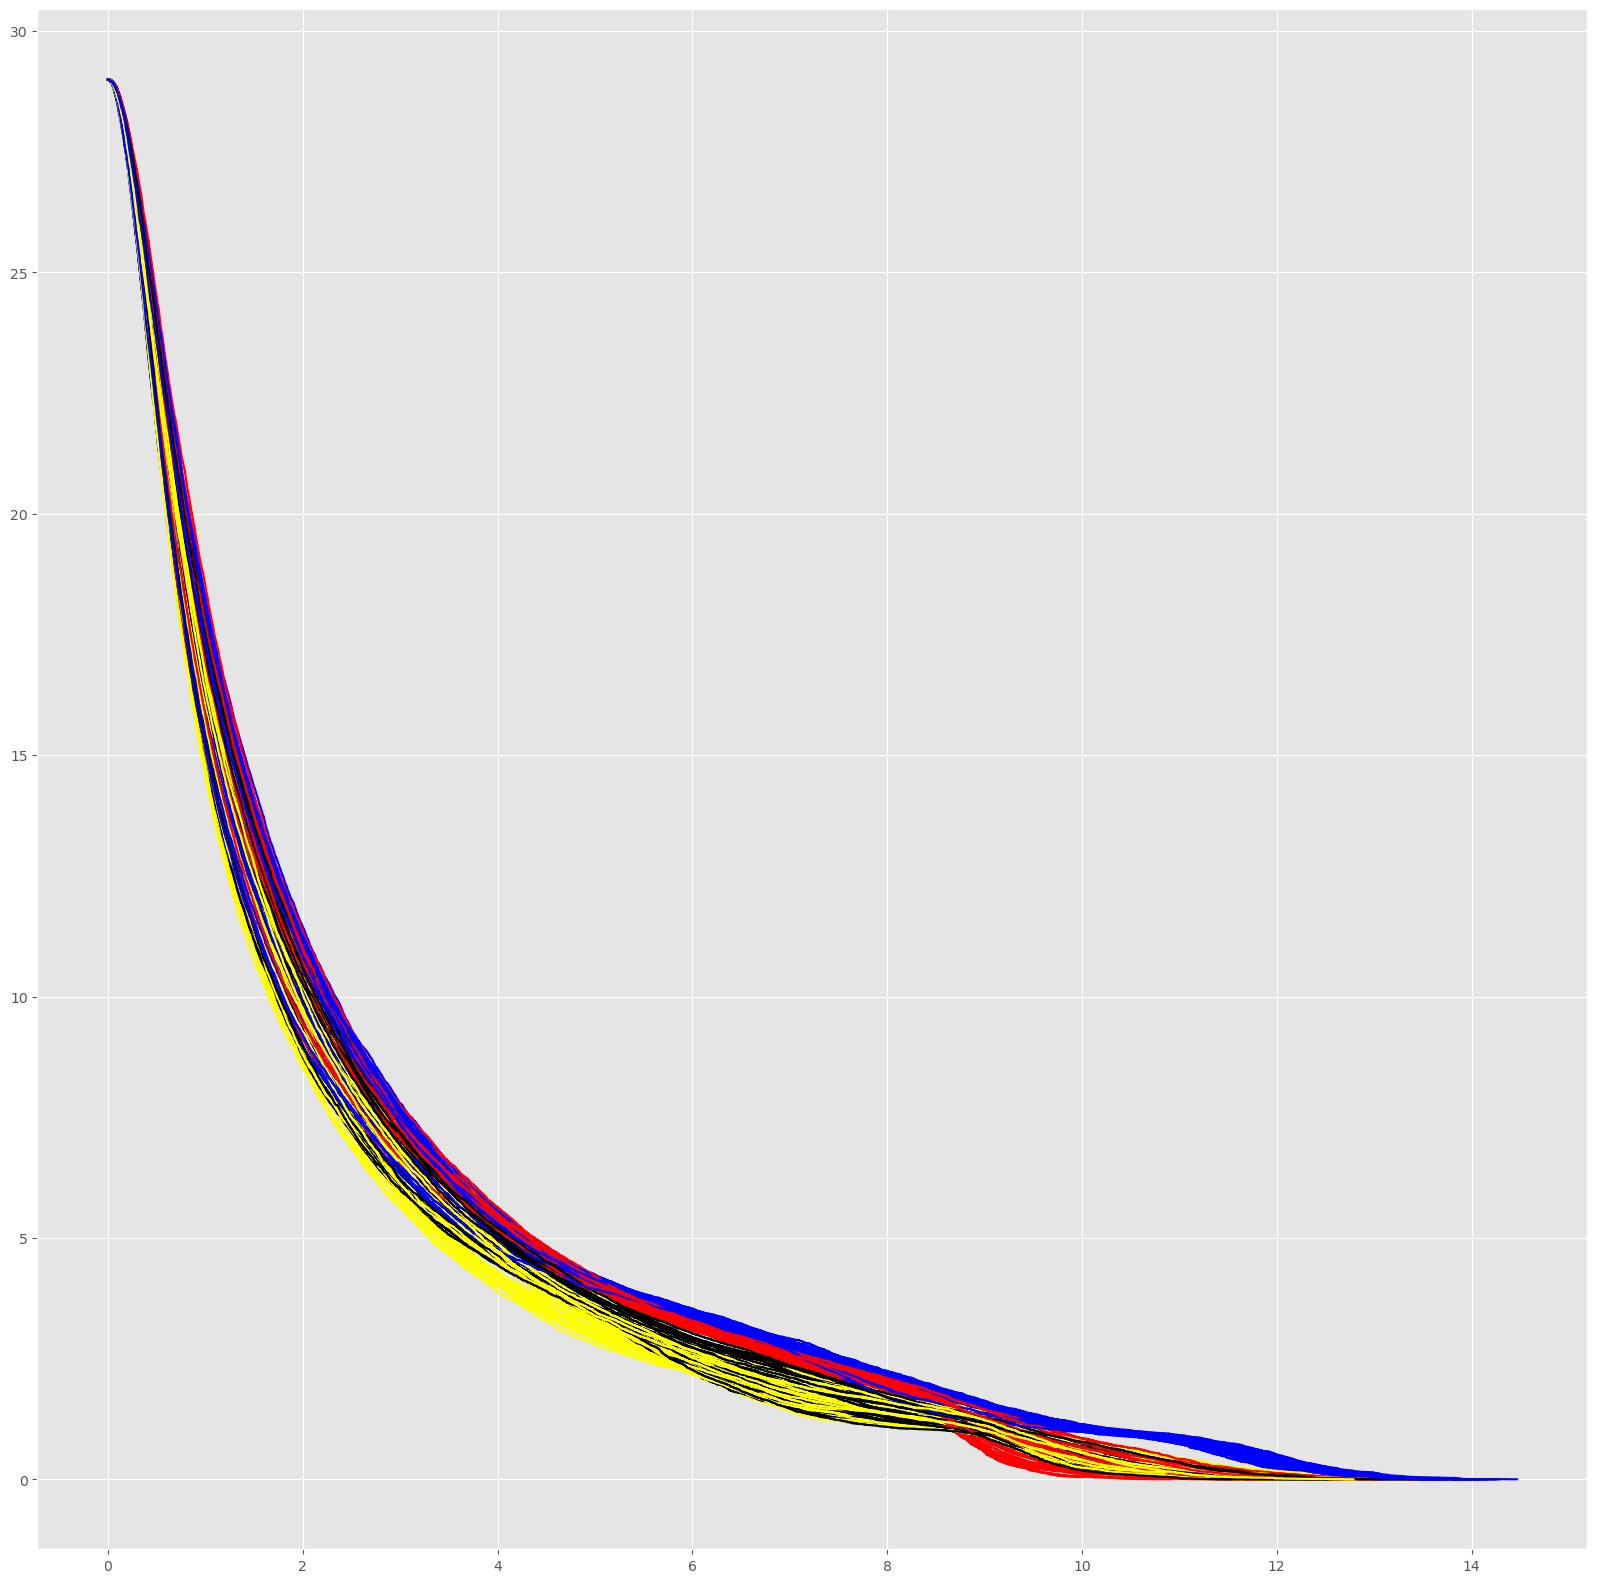

In [75]:
metric = "euclidean"
cm = "complete"
plt.figure(figsize=(20,20))

for i in range(0,50):
    s= sr.get_sample(500, sample_size=30, probabilities=800)
    figure = plain_figures_data.at[i,"figure"]
    dist = pdist(figure, "euclidean")
    D = sr.Distance(squareform(dist))
    f = D.get_h0sr(sample=s, clustering_method=cm)
    f.plot(color="red")
    
    s= sr.get_sample(500, sample_size=30, probabilities=800)
    figure = plain_figures_data.at[1000 + i,"figure"]
    dist = pdist(figure, "euclidean")
    D = sr.Distance(squareform(dist))
    g = D.get_h0sr(sample=s, clustering_method=cm)
    g.plot(color="black")
    
    s= sr.get_sample(500, sample_size=30, probabilities=800)
    figure = plain_figures_data.at[2000 + i,"figure"]
    dist = pdist(figure, "euclidean")
    D = sr.Distance(squareform(dist))
    g = D.get_h0sr(sample=s, clustering_method=cm)
    g.plot(color="yellow")
    
    s= sr.get_sample(500, sample_size=30, probabilities=800)
    figure = plain_figures_data.at[3000 + i,"figure"]
    dist = pdist(figure, "euclidean")
    D = sr.Distance(squareform(dist))
    g = D.get_h0sr(sample=s, clustering_method=cm)
    g.plot(color="blue")
    